# Inside `tls_masked_search`: zoom out → one star → result → zoom out

Start with the **entire saved collection**, understand what each table represents, pull out **TOI-880 / TIC 34077285** as one benchmark entry, follow its real light curve through the search, and put its results back into the aggregate. Then trace one actual classifier-dataset entry from its stored signal measurements to a freshly computed held-out score, before returning to the full classifier evaluation.

There are **two disjoint cohorts**, not one continuous training sample:

| Cohort / stage | Actual implementation | What we can execute here |
|---|---|---|
| 100-star benchmark | `01_benchmark.py`: one sector, 0.5–12 d, wide TLS, transit-masked flattening, fine TLS, second signal | Recompute TOI-880 from its locally cached FITS, then compare all 100 saved results |
| Larger labeled collection | `02_build_dataset.py`: up to two runs of four consecutive sectors, 0.5–30 d, two searches per run, merge/refine; **no transit-masked re-flattening** | Inspect saved star/signal tables; this machine does not currently have the collection's raw FITS |
| Classifier subset | `03_train_trees.py`: select signal labels, derive features, cross-validate grouped by star | Recompute feature preparation and grouped classifier evaluation from local CSVs |

**Reading route:** collection census → table relationships and data availability → choose one benchmark row → flux transformations → two detected signals → one-star result → aggregate benchmark → multi-sector dataset and labels → choose one training signal → features and held-out score → aggregate classifier performance.

Star, sector, transit event, detected signal and training example are different units. One star may have multiple sectors, one detected signal may have many transit events, and one star may contribute multiple classifier rows. The opening census makes these distinctions explicit.

Run all cells in the project environment. Everything required is local; only if TOI-880's benchmark FITS is missing will its existing downloader fetch that one target. No bulk dataset download is performed. The saved catalog labels and aggregate outcomes are used for orientation and evaluation; the live TLS searches receive **no catalog orbital periods, epochs or labels**.

In [1]:
from pathlib import Path
import hashlib
import importlib.util
import json
import os
import platform
import subprocess
import sys
import time
import warnings

# Find the project whether Jupyter starts at the root or in notebooks/.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'tls_masked_search/common.py').exists())
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / 'tls_masked_search'))
os.environ.setdefault('OMP_NUM_THREADS', '2')
os.environ.setdefault('OPENBLAS_NUM_THREADS', '2')
warnings.filterwarnings('ignore', message='Warning: the tpfmodel submodule.*')

import lightkurve as lk
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from astropy.io import fits
from IPython.display import display, Markdown
from transitleastsquares import transitleastsquares
import common
from tess_hunt.photometry import download_target, preprocess
from tess_hunt.search import phase_offset, vet_signal

def load_script(name, filename):
    spec = importlib.util.spec_from_file_location(name, ROOT / 'tls_masked_search' / filename)
    module = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(module)   # main() is guarded, so no downloads or runs here.
    return module

benchmark = load_script('masked_benchmark', '01_benchmark.py')
dataset = load_script('masked_dataset', '02_build_dataset.py')
classifier = load_script('masked_classifier', '03_train_trees.py')
CONFIG = json.loads((ROOT / 'config/benchmark.json').read_text())
FIGURES = ROOT / 'reports/walkthrough/figures/masked_tls'
FIGURES.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.figsize': (11, 4), 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.18})
COLORS = ['#2269a8', '#d6791a', '#25866e', '#a44265']

def show(fig, name):
    fig.tight_layout()
    fig.savefig(FIGURES / f'{name}.png', dpi=140, bbox_inches='tight')
    plt.show()
    plt.close(fig)

def ppm(flux):
    return (np.asarray(flux) - 1) * 1e6

def describe_fit(result, label, detection_sde=None):
    return {'stage': label, 'period_days': float(result.period), 't0_btjd': float(result.T0),
            'duration_hours': float(result.duration * 24),
            'TLS_bottom_depth_ppm': float((1 - result.depth) * 1e6),
            'SDE_this_grid': float(result.SDE),
            'wide_detection_SDE': float(result.SDE if detection_sde is None else detection_sde)}

source_files = ['common.py', '01_benchmark.py',
                '02_build_dataset.py', '03_train_trees.py']
provenance = {'git_commit': subprocess.check_output(['git', 'rev-parse', 'HEAD'], cwd=ROOT, text=True).strip(),
              'python': platform.python_version(),
              'source_sha256': {f: hashlib.sha256((ROOT / 'tls_masked_search' / f).read_bytes()).hexdigest()
                                for f in source_files}}
display(pd.Series({'Python': provenance['python'], 'Lightkurve': lk.__version__,
                   'Git source commit': provenance['git_commit'], 'Project': str(ROOT)}).to_frame('value'))

,value
Python,3.12.3
Lightkurve,2.6.0
Git source commit,06d7c328b45b54b6c97feb704bc9b1d74c500152
Project,/home/AMD/absheikh/exoplanets-main


## 0. Zoom out first: a snapshot of the entire saved collection

This is the dataset available to this project, not the full TESS mission. We load the saved catalogs and outputs before choosing an example. The tables below are a **snapshot of completed runs**; observing counts for the larger dataset describe Abdullah's run and do not imply that its raw observations are on this computer.

The reference catalog can contain many TOIs for one star. Selection chooses stars; a search produces signal rows; labeling retains some signal rows for training. The benchmark is a separate evaluation/learning cohort, excluded from classifier training.

In [2]:
snapshot_targets = pd.read_csv(ROOT / 'data/benchmark/targets.csv')
snapshot_benchmark = pd.read_csv(common.OUT_DIR / 'benchmark_100.csv')
snapshot_hosts = pd.read_csv(common.OUT_DIR / 'benchmark_100_hosts.csv')
snapshot_stars = pd.read_csv(common.OUT_DIR / 'dataset_stars.csv')
snapshot_signals = pd.read_csv(common.OUT_DIR / 'dataset_signals.csv')
snapshot_scores = pd.read_csv(common.OUT_DIR / 'classifier_scores.csv')
snapshot_tois = pd.read_csv(ROOT / 'data/dataset/toi_labeled.csv')

assert snapshot_targets.tic.is_unique and snapshot_stars.tic.is_unique
assert not set(snapshot_targets.tic).intersection(snapshot_stars.tic)
assert not snapshot_signals.duplicated(['tic', 'signal']).any()
assert not snapshot_scores.duplicated(['tic', 'signal']).any()
assert set(snapshot_scores.tic).issubset(set(snapshot_signals.tic))
assert set(snapshot_signals.tic).issubset(set(snapshot_stars.tic))

snapshot_tables = pd.DataFrame([
    {'table': 'TOI reference snapshot', 'unit of one row': 'Catalog TOI', 'rows': len(snapshot_tois),
     'distinct stars': snapshot_tois.tid.nunique(), 'key / join': 'tid (TIC), toi'},
    {'table': 'Benchmark targets', 'unit of one row': 'Selected star + one sector', 'rows': len(snapshot_targets),
     'distinct stars': snapshot_targets.tic.nunique(), 'key / join': 'tic'},
    {'table': 'Benchmark search results', 'unit of one row': 'Star, with signal 1 and 2 columns', 'rows': len(snapshot_benchmark),
     'distinct stars': snapshot_benchmark.tic.nunique(), 'key / join': 'tic'},
    {'table': 'Larger dataset: stars', 'unit of one row': 'Selected star', 'rows': len(snapshot_stars),
     'distinct stars': snapshot_stars.tic.nunique(), 'key / join': 'tic'},
    {'table': 'Larger dataset: signals', 'unit of one row': 'Detected candidate pattern', 'rows': len(snapshot_signals),
     'distinct stars': snapshot_signals.tic.nunique(), 'key / join': 'tic + signal'},
    {'table': 'Classifier examples + saved scores', 'unit of one row': 'Label-eligible detected signal', 'rows': len(snapshot_scores),
     'distinct stars': snapshot_scores.tic.nunique(), 'key / join': 'tic + signal'},
])
display(snapshot_tables)

benchmark_raw = [ROOT / 'data/raw/benchmark' / name for name in snapshot_targets.filename]
dataset_raw = list((ROOT / 'data/raw/dataset').glob('*.fits'))
availability = pd.DataFrame([
    {'cohort': 'Benchmark', 'stars selected': len(snapshot_targets),
     'stars with data in saved run': len(snapshot_targets),
     'FITS sectors in saved run': len(snapshot_targets),
     'raw FITS present locally': sum(p.is_file() for p in benchmark_raw),
     'saved run raw size [GB]': sum(p.stat().st_size for p in benchmark_raw if p.is_file()) / 1e9},
    {'cohort': 'Larger labeled collection', 'stars selected': len(snapshot_stars),
     'stars with data in saved run': int(snapshot_stars.sectors.gt(0).sum()),
     'FITS sectors in saved run': int(snapshot_stars.sectors.fillna(0).sum()),
     'raw FITS present locally': len(dataset_raw),
     'saved run raw size [GB]': snapshot_stars.download_mb.sum() / 1000},
])
display(availability)
print('All catalog, signal-feature and score tables above are local. Raw FITS availability is a separate question.')

,table,unit of one row,rows,distinct stars,key / join
0,TOI reference snapshot,Catalog TOI,8146,7824,"tid (TIC), toi"
1,Benchmark targets,Selected star + one sector,100,100,tic
2,Benchmark search results,"Star, with signal 1 and 2 columns",100,100,tic
3,Larger dataset: stars,Selected star,2454,2454,tic
4,Larger dataset: signals,Detected candidate pattern,5554,2204,tic + signal
5,Classifier examples + saved scores,Label-eligible detected signal,1725,1663,tic + signal


,cohort,stars selected,stars with data in saved run,FITS sectors in saved run,raw FITS present locally,saved run raw size [GB]
0,Benchmark,100,100,100,100,0.205934
1,Larger labeled collection,2454,2204,7435,15986,14.482610


All catalog, signal-feature and score tables above are local. Raw FITS availability is a separate question.


### How the rows flow through the pipeline

The census below keeps **stars** separate from **signal rows**. Lack of two-minute data eliminates stars before a search. Label eligibility eliminates signals after a search. A signal can be retained without passing SDE ≥ 7: the dataset builder records candidates before the classifier decides what to accept.

These counts include both positive and negative examples. A classifier dataset is not a list of discovered planets, and an unmatched signal is not automatically a false alarm.

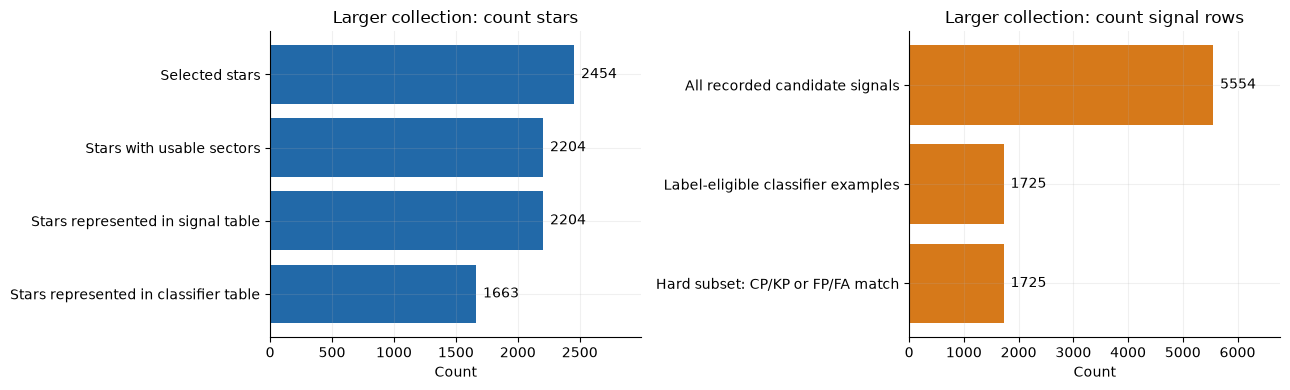

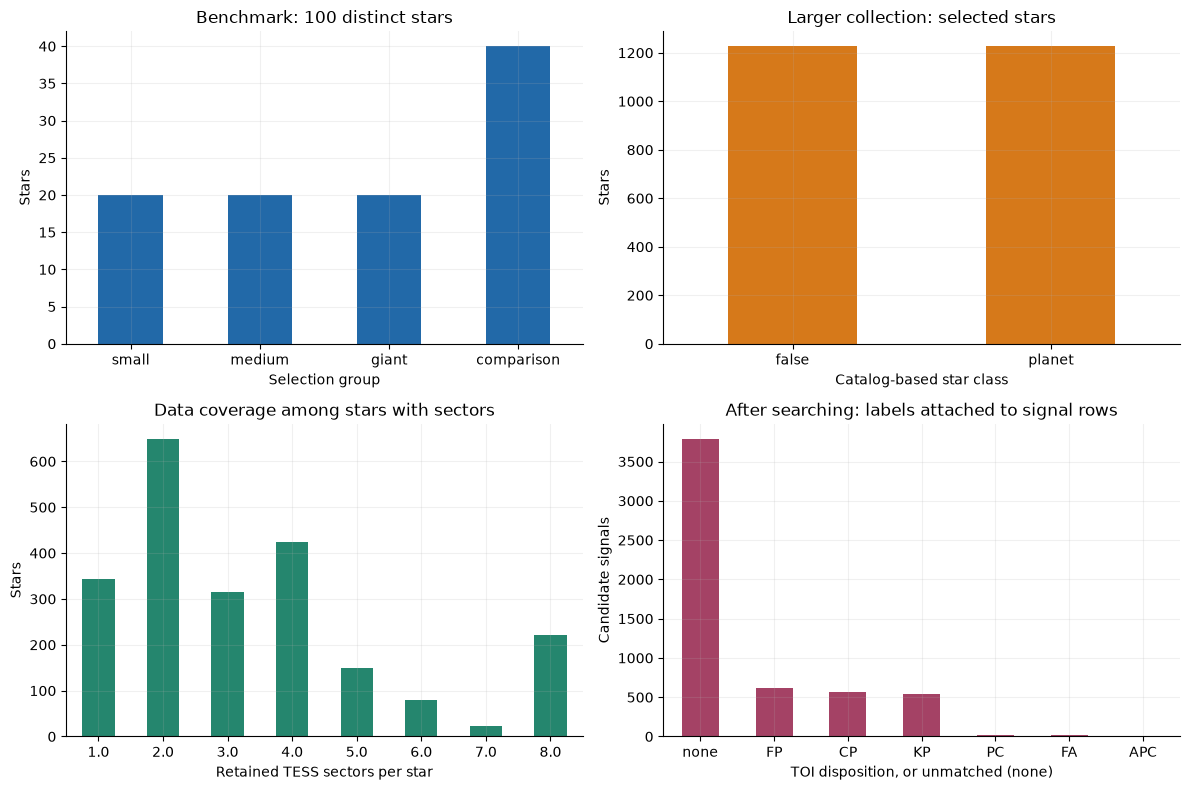

In [3]:
star_census = pd.Series({
    'Selected stars': len(snapshot_stars),
    'Stars with usable sectors': int(snapshot_stars.sectors.gt(0).sum()),
    'Stars represented in signal table': snapshot_signals.tic.nunique(),
    'Stars represented in classifier table': snapshot_scores.tic.nunique(),
})
signal_census = pd.Series({
    'All recorded candidate signals': len(snapshot_signals),
    'Label-eligible classifier examples': len(snapshot_scores),
    'Hard subset: CP/KP or FP/FA match': int(snapshot_scores.hard.sum()),
})
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for axis, census, title, color in zip(ax, [star_census, signal_census],
        ['Larger collection: count stars', 'Larger collection: count signal rows'], COLORS[:2]):
    positions = np.arange(len(census))
    bars = axis.barh(positions, census.values, color=color)
    axis.set(yticks=positions, yticklabels=census.index, xlabel='Count', title=title,
             xlim=(0, census.max() * 1.22))
    axis.invert_yaxis()
    axis.bar_label(bars, padding=5, fmt='%.0f')
show(fig, '00a_dataset_census')

fig, ax = plt.subplots(2, 2, figsize=(12, 8))
snapshot_targets.radius_bin.value_counts().reindex(['small', 'medium', 'giant', 'comparison']).plot.bar(
    ax=ax[0, 0], color=COLORS[0])
ax[0, 0].set(title='Benchmark: 100 distinct stars', ylabel='Stars', xlabel='Selection group')
snapshot_stars.groupby('star_class').size().plot.bar(ax=ax[0, 1], color=COLORS[1])
ax[0, 1].set(title='Larger collection: selected stars', ylabel='Stars', xlabel='Catalog-based star class')
snapshot_stars.sectors.value_counts().sort_index().plot.bar(ax=ax[1, 0], color=COLORS[2])
ax[1, 0].set(title='Data coverage among stars with sectors', ylabel='Stars', xlabel='Retained TESS sectors per star')
snapshot_signals.label.value_counts().plot.bar(ax=ax[1, 1], color=COLORS[3])
ax[1, 1].set(title='After searching: labels attached to signal rows', ylabel='Candidate signals', xlabel='TOI disposition, or unmatched (none)')
for axis in ax.flat:
    axis.tick_params(axis='x', rotation=0)
show(fig, '00b_dataset_distributions')

### Choose one entry and keep track of where it came from

We now pull **one row from `Benchmark targets`**: TOI-880. Its raw observations are local, so we can actually recompute the flux-to-signal path rather than merely inspect a saved result. It sits in the medium-planet-size selection group; that group is catalog metadata used to choose the example, not an input to TLS.

The larger classifier collection is a separate cohort. Later we select one of its actual signal rows to follow the feature-to-score path. We will not fabricate a classifier score for TOI-880, which was excluded from that collection.

,tic,hostname,catalog_group,radius_bin,sector,tmag,mass,radius
7,34077285,TOI-880,known_transiting_host,medium,107,9.2563,0.87,0.83


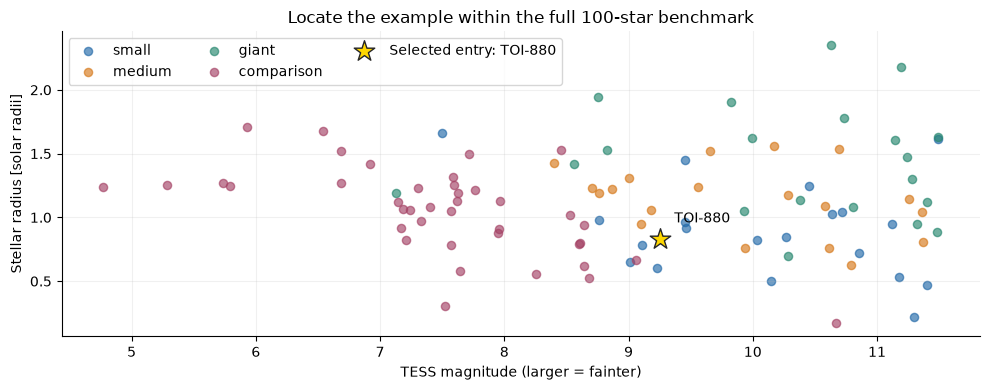

In [4]:
TIC = 34077285
selected_target = snapshot_targets.loc[snapshot_targets.tic.eq(TIC)]
assert len(selected_target) == 1
assert TIC not in set(snapshot_stars.tic)
display(selected_target[['tic', 'hostname', 'catalog_group', 'radius_bin', 'sector', 'tmag', 'mass', 'radius']])
target = selected_target.iloc[0].to_dict()

fig, ax = plt.subplots(figsize=(10, 4))
for group, color in zip(['small', 'medium', 'giant', 'comparison'], COLORS):
    g = snapshot_targets[snapshot_targets.radius_bin.eq(group)]
    ax.scatter(g.tmag, g.radius, s=35, alpha=.65, color=color, label=group)
ax.scatter([target['tmag']], [target['radius']], s=240, marker='*', facecolor='gold',
           edgecolor='0.15', zorder=5, label='Selected entry: TOI-880')
ax.annotate('TOI-880', (target['tmag'], target['radius']), xytext=(10, 12), textcoords='offset points')
ax.set(xlabel='TESS magnitude (larger = fainter)', ylabel='Stellar radius [solar radii]',
       title='Locate the example within the full 100-star benchmark')
ax.legend(ncol=3)
show(fig, '00c_selected_star_context')

## 1. Zoom in: turn the selected star into a light curve

A light curve measures the summed flux in one star's aperture over time. `PDCSAP_FLUX` has SPOC's corrections; `SAP_FLUX` is the aperture flux before those corrections. Neither is a whole-camera brightness measurement.

`lk.read(..., flux_column="pdcsap_flux")` applies Lightkurve's default TESS quality mask. `remove_nans()` then drops missing flux values. We inspect the original FITS rows as well, so the discarded samples remain visible. Times are **BTJD = BJD − 2,457,000**, in TDB days.

,value
target,TOI-880
TIC,34077285
sector,107
observation start (TDB),2026-08-09T14:24:05.208
observation end (TDB),2026-09-07T06:30:43.029
original FITS rows,20656
rows after lk.read quality mask,18729
finite-flux rows,15037
FITS SHA-256,75d61dd10ad0ac319018216d92202b0e5b37c2377c7bf7...


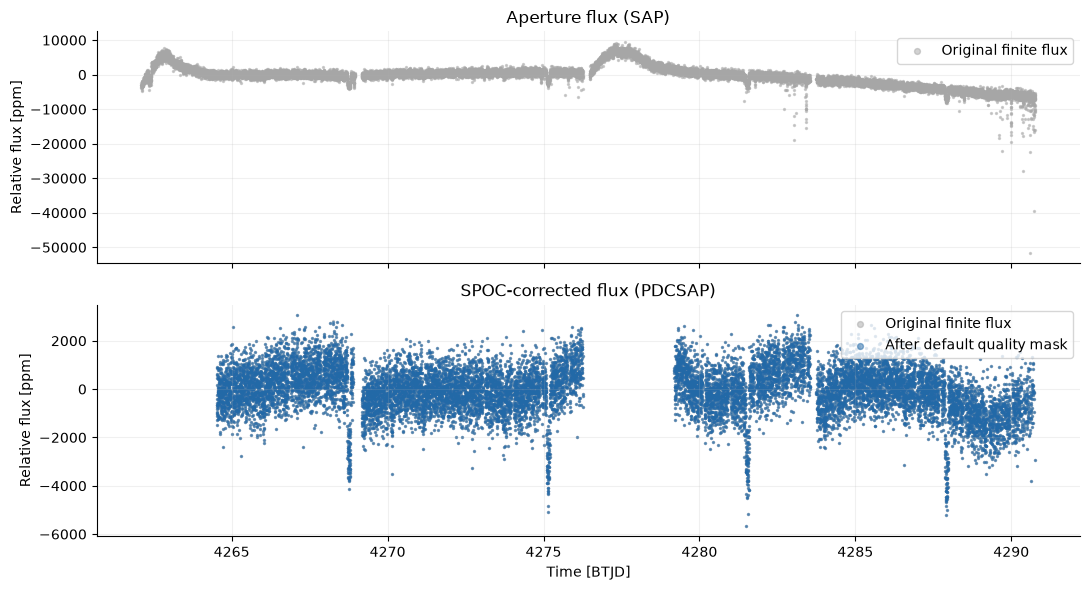

In [5]:
targets = snapshot_targets
# target and TIC come from the selected dataset entry above.
path = ROOT / 'data/raw/benchmark' / target['filename']
if not path.exists():
    download_target(ROOT, target)
provenance['fits_sha256'] = hashlib.sha256(path.read_bytes()).hexdigest()
with fits.open(path) as hdul:
    raw = pd.DataFrame({name: np.array(hdul[1].data[name], dtype=float)
                        for name in ['TIME', 'SAP_FLUX', 'PDCSAP_FLUX', 'PDCSAP_FLUX_ERR', 'QUALITY']})
    date_start, date_end = hdul[0].header['DATE-OBS'], hdul[0].header['DATE-END']
lc = lk.read(path, flux_column='pdcsap_flux')
display(pd.Series({'target': target['hostname'], 'TIC': TIC, 'sector': target['sector'],
                   'observation start (TDB)': date_start, 'observation end (TDB)': date_end,
                   'original FITS rows': len(raw), 'rows after lk.read quality mask': len(lc),
                   'finite-flux rows': len(lc.remove_nans()), 'FITS SHA-256': provenance['fits_sha256']}).to_frame('value'))

fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
for axis, column, title in zip(ax, ['SAP_FLUX', 'PDCSAP_FLUX'], ['Aperture flux (SAP)', 'SPOC-corrected flux (PDCSAP)']):
    norm = raw[column] / raw[column].median()
    axis.scatter(raw.TIME, ppm(norm), s=2, color='0.65', alpha=.5, label='Original finite flux')
    if column == 'PDCSAP_FLUX':
        axis.scatter(lc.time.value, ppm(lc.flux.value / np.nanmedian(lc.flux.value)),
                     s=2, color=COLORS[0], alpha=.5, label='After default quality mask')
    axis.set(ylabel='Relative flux [ppm]', title=title)
    axis.legend(loc='upper right', markerscale=3)
ax[-1].set_xlabel('Time [BTJD]')
show(fig, '01_original_flux')

## 2. Open up `clean_and_stitch`

The cleaning recipe normalizes by the median, estimates a slow trend with Lightkurve's Savitzky–Golay flattening, and divides both flux and uncertainty by that trend. Its **1,001-point window is about 33 hours at two-minute cadence**. This width is expressed in samples, so changing the cadence changes its physical timescale. Gaps and clipping also affect the fitted trend.

Only large **upward** outliers are removed (`sigma=6`, `sigma_lower=np.inf`), preserving downward dips for the search. Ten-minute binning reduces the number of samples. Here Lightkurve uses arithmetic mean flux, bin-center time, and propagated formal errors; this differs from the inverse-variance binning in the original `tess_hunt` pipeline. Empty bins are discarded rather than filled with synthetic flux.

[Lightkurve's flatten documentation](https://lightkurve.github.io/lightkurve/reference/api/lightkurve.LightCurve.flatten.html) explains how the smoothing and optional mask work.

,stage,samples
0,FITS,20656
1,quality mask,18729
2,finite flux + normalization,15037
3,upward clipping,15037
4,occupied ten-minute bins,3158


Upward outliers removed: 0; nominal window: 33.37 h


,time_btjd,normalized_flux,formal_flux_error
0,4264.523204,1.000303,0.000770
1,4264.530149,1.000001,0.000770
2,4264.537093,0.999762,0.000770
3,4264.544038,0.999743,0.000769
4,4264.550982,1.000290,0.000769
5,4264.557927,1.000054,0.000769
6,4264.564871,0.999907,0.000769
7,4264.571816,1.000118,0.000769


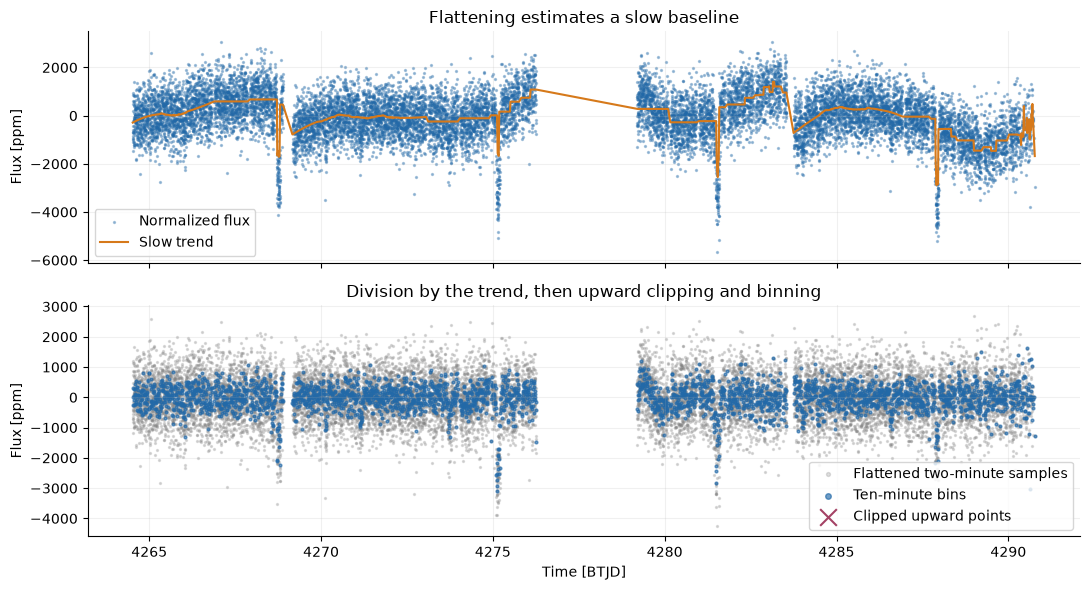

In [6]:
normalized = lc.remove_nans().normalize()
flat, trend = normalized.flatten(window_length=1001, return_trend=True)
clipped, upward_outliers = flat.remove_outliers(sigma=6, sigma_lower=np.inf, return_mask=True)
unfiltered_bins = lk.LightCurveCollection([clipped]).stitch().bin(time_bin_size=CONFIG['bin_minutes'] / 1440)
binned = unfiltered_bins.remove_nans()
t, y, dy = (a.value.astype(float) for a in [binned.time, binned.flux, binned.flux_err])

# Check the expanded steps against the production helper, not a different cleaning recipe.
for actual, expected in zip((t, y, dy), common.clean_and_stitch([lc], CONFIG['bin_minutes'])):
    np.testing.assert_allclose(actual, expected, rtol=1e-12, atol=1e-12)
assert np.all(np.isfinite(dy)) and np.all(dy > 0)
display(pd.DataFrame({'stage': ['FITS', 'quality mask', 'finite flux + normalization',
                              'upward clipping', 'occupied ten-minute bins'],
                      'samples': [len(raw), len(lc), len(normalized), len(clipped), len(t)]}))
print(f"Upward outliers removed: {upward_outliers.sum()}; "
      f"nominal window: {1001 * np.median(np.diff(normalized.time.value)) * 24:.2f} h")
display(pd.DataFrame({'time_btjd': t[:8], 'normalized_flux': y[:8], 'formal_flux_error': dy[:8]}))

fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
ax[0].scatter(normalized.time.value, ppm(normalized.flux.value), s=2, alpha=.35, color=COLORS[0], label='Normalized flux')
ax[0].plot(trend.time.value, ppm(trend.flux.value), color=COLORS[1], lw=1.5, label='Slow trend')
ax[0].set(ylabel='Flux [ppm]', title='Flattening estimates a slow baseline')
ax[0].legend()
ax[1].scatter(flat.time.value, ppm(flat.flux.value), s=2, alpha=.25, color='0.5', label='Flattened two-minute samples')
ax[1].scatter(t, ppm(y), s=4, alpha=.65, color=COLORS[0], label='Ten-minute bins')
ax[1].scatter(flat.time.value[upward_outliers], ppm(flat.flux.value[upward_outliers]),
              marker='x', color=COLORS[3], label='Clipped upward points')
ax[1].set(xlabel='Time [BTJD]', ylabel='Flux [ppm]', title='Division by the trend, then upward clipping and binning')
ax[1].legend(markerscale=2)
show(fig, '02_cleaning')

## 3. Wide TLS: discover a repeating shape

TLS tries trial periods, epochs and durations, looking for a repeating transit-shaped decrease in flux. Stellar mass/radius priors constrain its search grids; the generic limb-darkening coefficients describe the assumed template rather than a measured stellar atmosphere.

The benchmark searches **0.5–12 days**, capped at half the usable time span. `n_transits_min=2` constrains the search range; it does not guarantee that two actual events were observed in gaps. We check observed events later. The **SDE ≥ 7** rule is a heuristic screening cutoff, not a calibrated probability that a signal is real. [TLS's Python interface](https://transitleastsquares.readthedocs.io/en/latest/Python%20interface.html) describes the grids and returned statistics.

For this walkthrough we limit TLS to two threads; all scientific settings remain those of `common.py`.

TLS emits a **period-grid fallback warning** on this run. Its grid generator uses solar mass/radius for sampling when too few trial periods remain. The warning is retained in the outputs; the notebook follows the production helper rather than silently changing its settings. This concerns grid sampling and does not mean the supplied stellar priors were measured from the transit.

,TLS setting
R_star,0.83
R_star_min,0.664
R_star_max,0.996
M_star,0.87
M_star_min,0.696
M_star_max,1.044
u,"[0.3, 0.2]"
use_threads,2
show_progress_bar,False
verbose,False


/home/AMD/absheikh/exoplanets/.venv/lib/python3.12/site-packages/transitleastsquares/grid.py:196: UserWarning: period_grid defaults to R_star=1 and M_star=1 as given density yielded grid with too few values
  warnings.warn(


Wide search: 2,958 trial periods, 0.50–12.00 d, 0.51 s


,stage,period_days,t0_btjd,duration_hours,TLS_bottom_depth_ppm,SDE_this_grid,wide_detection_SDE
0,Signal 1: wide search,6.390893,4268.754109,2.931809,1610.243102,17.620148,17.620148


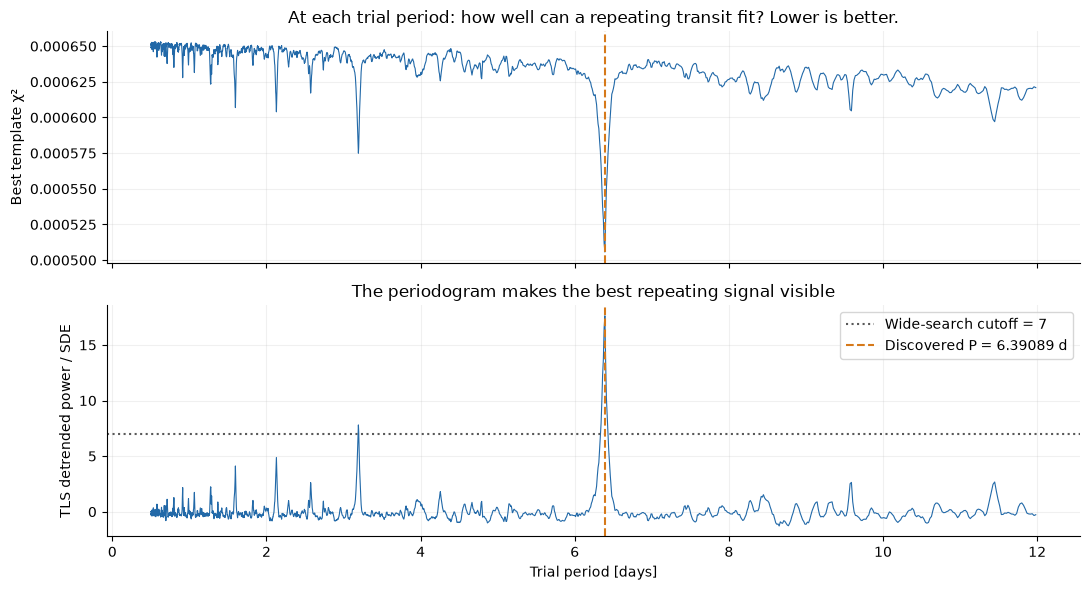

In [7]:
star = {**common.star_kwargs(float(target['mass']), float(target['radius'])), 'use_threads': 2}
display(pd.Series(star).to_frame('TLS setting'))
start = time.perf_counter()
wide1, pmax = common.tls_wide(t, y, dy, star, CONFIG)
print(f'Wide search: {len(wide1.periods):,} trial periods, '
      f"{CONFIG['period_min_days']:.2f}–{pmax:.2f} d, {time.perf_counter() - start:.2f} s")
display(pd.DataFrame([describe_fit(wide1, 'Signal 1: wide search')]))

fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
ax[0].plot(wide1.periods, wide1.chi2, color=COLORS[0], lw=.8)
ax[0].axvline(wide1.period, color=COLORS[1], ls='--')
ax[0].set(ylabel='Best template χ²', title='At each trial period: how well can a repeating transit fit? Lower is better.')
ax[1].plot(wide1.periods, wide1.power, color=COLORS[0], lw=.8)
ax[1].axhline(common.MIN_SDE, color='0.35', ls=':', label='Wide-search cutoff = 7')
ax[1].axvline(wide1.period, color=COLORS[1], ls='--', label=f'Discovered P = {wide1.period:.5f} d')
ax[1].set(xlabel='Trial period [days]', ylabel='TLS detrended power / SDE', title='The periodogram makes the best repeating signal visible')
ax[1].legend()
show(fig, '03_wide_search')

## 4. Mask while fitting the trend: retain the transits

The first trend can follow some of a dip and absorb its depth. We now predict transit windows **from the wide search's own period and epoch**, exclude those windows from the trend fit, and flatten the original flux again. The dips themselves remain in the output light curve.

The excluded window has total width **twice the wide-fit duration**. Lightkurve estimates the trend through the masked region from the remaining data. This is interpolation of the baseline model, not insertion of new photometric observations. Whether it improves the transit measurement depends on the data and mask accuracy.

For a discovered period $P$ and epoch $T_0$, the centered phase-time coordinate is

$$\Delta t = ((t-T_0+P/2)\bmod P)-P/2.$$

The mask is $|\Delta t| < D$ for wide-fit duration $D$. Folding onto this coordinate stacks repeated events so their shapes can be compared.

676 samples excluded from trend fitting, but retained as possible transit data.


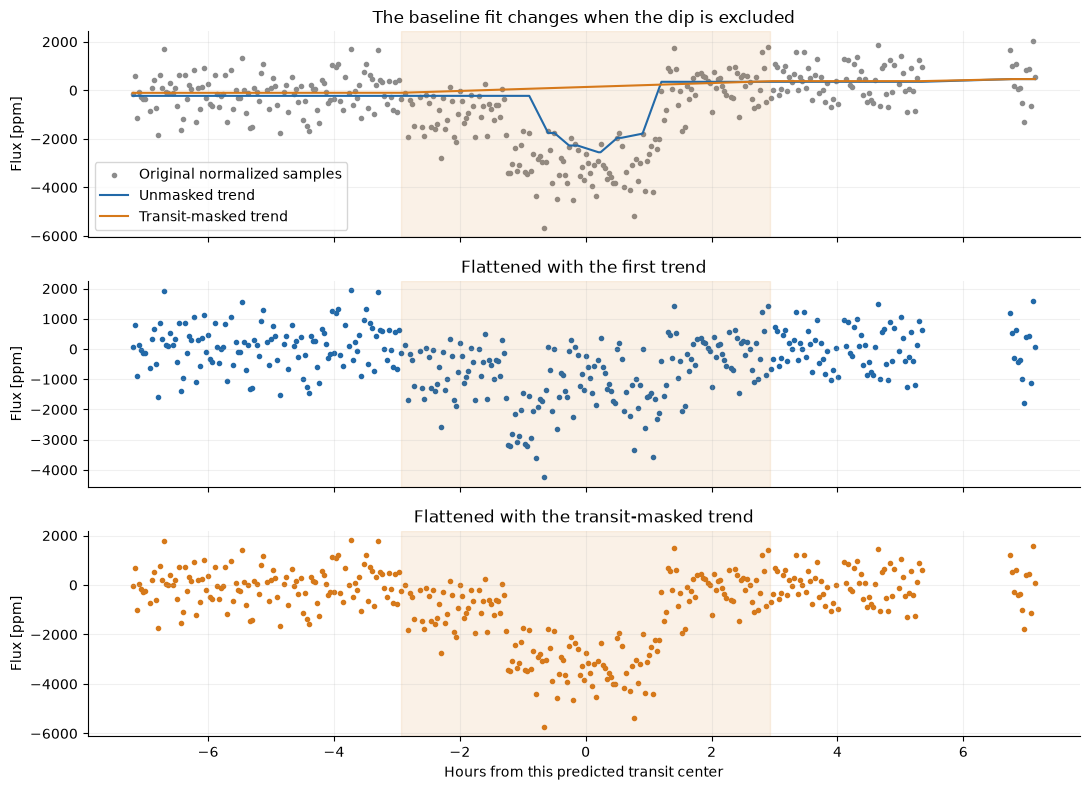

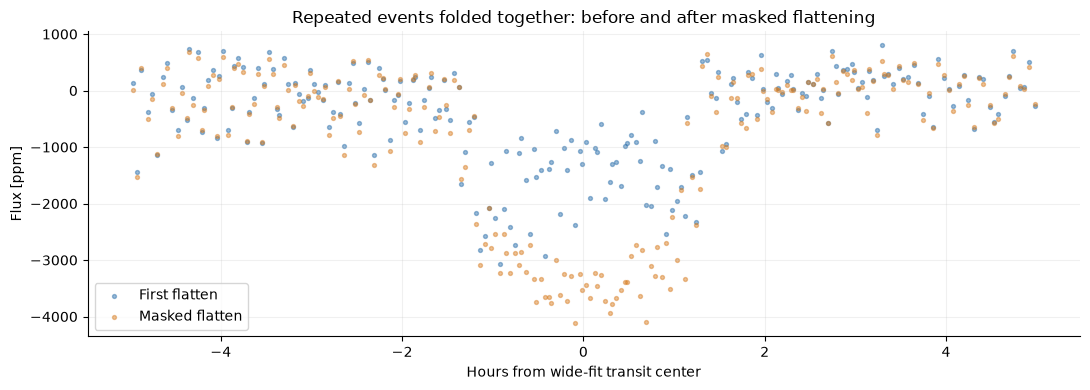

In [8]:
assert wide1.SDE >= common.MIN_SDE, 'This example requires a first signal that passes the wide-search threshold.'
transit_mask1 = normalized.create_transit_mask(period=wide1.period, transit_time=wide1.T0,
                                              duration=2 * wide1.duration)
flat_masked, trend_masked = normalized.flatten(window_length=1001, mask=transit_mask1, return_trend=True)
clip_masked = flat_masked.remove_outliers(sigma=6, sigma_lower=np.inf)
bins_masked = lk.LightCurveCollection([clip_masked]).stitch().bin(
    time_bin_size=CONFIG['bin_minutes'] / 1440).remove_nans()
tm, ym, dym = (a.value.astype(float) for a in [bins_masked.time, bins_masked.flux, bins_masked.flux_err])
for actual, expected in zip((tm, ym, dym), common.clean_and_stitch(
        [lc], CONFIG['bin_minutes'], ephemeris=(wide1.period, wide1.T0, wide1.duration))):
    np.testing.assert_allclose(actual, expected, rtol=1e-12, atol=1e-12)
print(f'{transit_mask1.sum():,} samples excluded from trend fitting, but retained as possible transit data.')

# Choose the predicted event with the most nearby actual samples for a useful local zoom.
cycles = np.arange(np.floor((normalized.time.value.min() - wide1.T0) / wide1.period),
                   np.ceil((normalized.time.value.max() - wide1.T0) / wide1.period) + 1)
centers = wide1.T0 + cycles * wide1.period
center = max(centers, key=lambda c: np.sum(np.abs(normalized.time.value - c) < .25))
local = np.abs(normalized.time.value - center) < .3
hours = (normalized.time.value - center) * 24

fig, ax = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
ax[0].scatter(hours[local], ppm(normalized.flux.value[local]), s=9, color='0.55', label='Original normalized samples')
ax[0].plot(hours[local], ppm(trend.flux.value[local]), color=COLORS[0], label='Unmasked trend')
ax[0].plot(hours[local], ppm(trend_masked.flux.value[local]), color=COLORS[1], label='Transit-masked trend')
ax[0].set(ylabel='Flux [ppm]', title='The baseline fit changes when the dip is excluded')
ax[0].legend()
for axis, curve, title, color in zip(ax[1:], [flat, flat_masked],
        ['Flattened with the first trend', 'Flattened with the transit-masked trend'], COLORS[:2]):
    axis.scatter(hours[local], ppm(curve.flux.value[local]), s=9, color=color)
    axis.set(ylabel='Flux [ppm]', title=title)
for axis in ax:
    axis.axvspan(-wide1.duration * 24, wide1.duration * 24, color=COLORS[1], alpha=.10)
ax[-1].set_xlabel('Hours from this predicted transit center')
show(fig, '04_masked_trend')

fig, ax = plt.subplots(figsize=(11, 4))
for tt, ff, label, color in [(t, y, 'First flatten', COLORS[0]), (tm, ym, 'Masked flatten', COLORS[1])]:
    phase_h = phase_offset(tt, wide1.period, wide1.T0) * 24
    zoom = np.abs(phase_h) < 5
    ax.scatter(phase_h[zoom], ppm(ff[zoom]), s=8, alpha=.45, label=label, color=color)
ax.set(xlabel='Hours from wide-fit transit center', ylabel='Flux [ppm]', title='Repeated events folded together: before and after masked flattening')
ax.legend()
show(fig, '05_folded_flattening_comparison')

## 5. Fine TLS: refine a discovered signal

The fine pass searches **±0.5% around the wide-fit period**, with period-grid oversampling increased to 20. This narrows the question to the neighborhood of an already discovered peak and measures its shape on the re-flattened flux.

The benchmark deliberately retains the **wide-search SDE for detection**. SDE is computed relative to the trial grid's background; a narrow-grid SDE cannot be substituted for the wide-grid screening statistic. TLS's `depth` is the flux level at the transit bottom; the displayed decrement is **`1 - depth`**, in ppm.

/home/AMD/absheikh/exoplanets/.venv/lib/python3.12/site-packages/transitleastsquares/grid.py:196: UserWarning: period_grid defaults to R_star=1 and M_star=1 as given density yielded grid with too few values
  warnings.warn(


,stage,period_days,t0_btjd,duration_hours,TLS_bottom_depth_ppm,SDE_this_grid,wide_detection_SDE
0,Wide: discovery,6.390893,4268.754109,2.931809,1610.243102,17.620148,17.620148
1,Fine: masked refinement,6.387223,4268.759773,2.759028,3295.436967,1.575603,17.620148


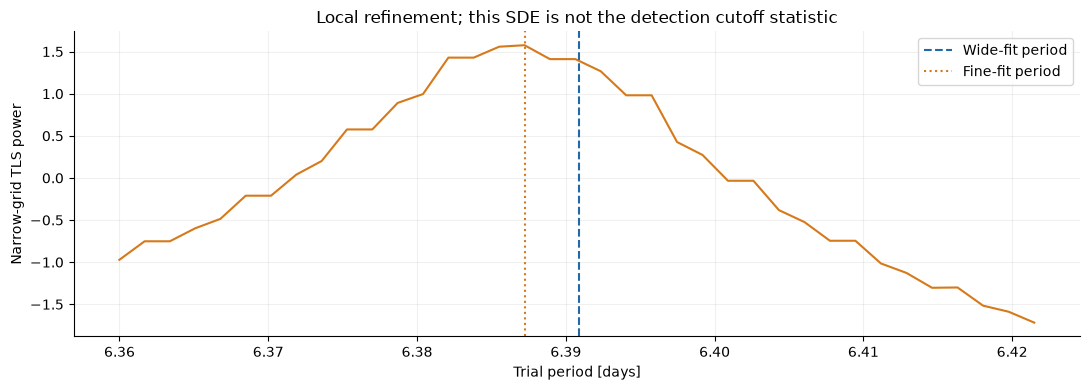

In [9]:
fine1 = transitleastsquares(tm, ym, dym).power(
    period_min=wide1.period * .995, period_max=min(wide1.period * 1.005, pmax),
    n_transits_min=2, oversampling_factor=20, **star)
display(pd.DataFrame([describe_fit(wide1, 'Wide: discovery'),
                      describe_fit(fine1, 'Fine: masked refinement', wide1.SDE)]))
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(fine1.periods, fine1.power, color=COLORS[1])
ax.axvline(wide1.period, color=COLORS[0], ls='--', label='Wide-fit period')
ax.axvline(fine1.period, color=COLORS[1], ls=':', label='Fine-fit period')
ax.set(xlabel='Trial period [days]', ylabel='Narrow-grid TLS power', title='Local refinement; this SDE is not the detection cutoff statistic')
ax.legend()
show(fig, '06_fine_search')

## 6. Hide the first signal: expose a weaker repeat pattern

This is a different use of a mask. `hide_transits` **removes photometric samples** around signal 1 from the original quality-filtered curve. It uses the **wide result**, with total mask width twice that duration, exactly as the benchmark script does. It does not subtract a fitted planet model.

The remaining samples go through a fresh wide search and, if they pass SDE ≥ 7, another masked flattening and fine search. This can reveal a second planet, but masking also loses data and can distort or remove overlapping events. Gaps stay gaps.

Removed 852 / 18,729 samples (4.5%) around signal 1.


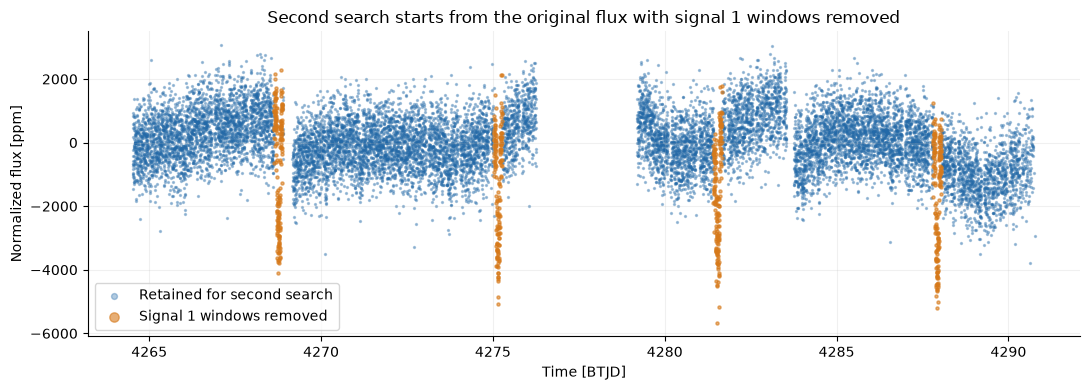

/home/AMD/absheikh/exoplanets/.venv/lib/python3.12/site-packages/transitleastsquares/grid.py:196: UserWarning: period_grid defaults to R_star=1 and M_star=1 as given density yielded grid with too few values
  warnings.warn(


,stage,period_days,t0_btjd,duration_hours,TLS_bottom_depth_ppm,SDE_this_grid,wide_detection_SDE
0,Signal 1: wide,6.390893,4268.754109,2.931809,1610.243102,17.620148,17.620148
1,Signal 1: fine,6.387223,4268.759773,2.759028,3295.436967,1.575603,17.620148
2,Signal 2: wide,2.573092,4266.006075,1.643019,602.133225,16.254690,16.254690
3,Signal 2: final,2.571609,4266.011179,1.600514,737.288775,1.604511,16.254690


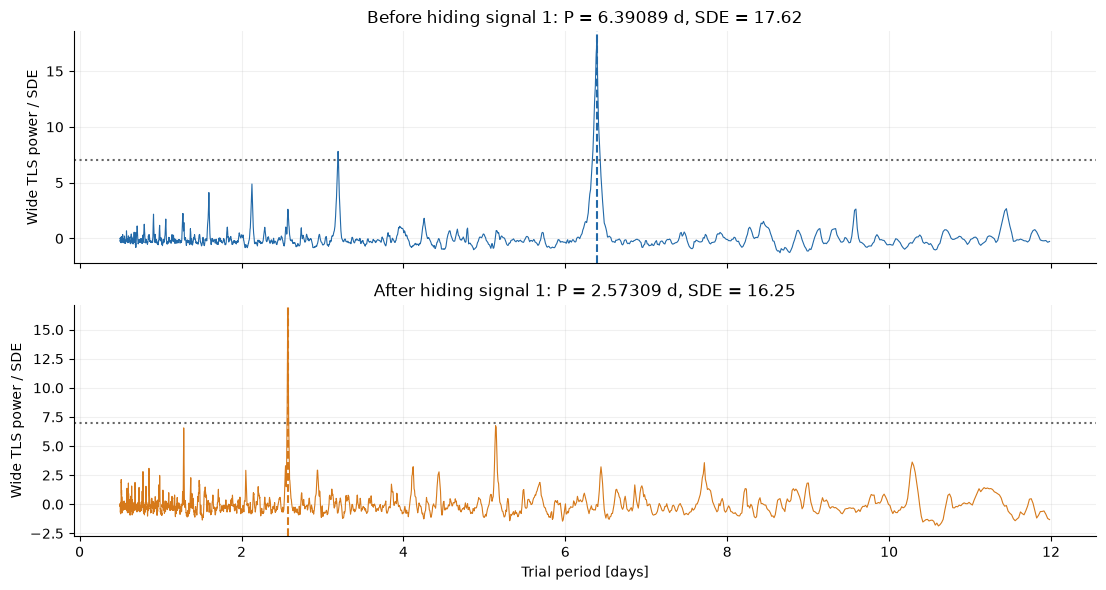

In [10]:
hide1 = lc.create_transit_mask(period=wide1.period, transit_time=wide1.T0, duration=2 * wide1.duration)
remaining = common.hide_transits(lc, wide1)
assert len(remaining) == len(lc) - hide1.sum()
print(f'Removed {hide1.sum():,} / {len(lc):,} samples ({hide1.mean():.1%}) around signal 1.')

fig, ax = plt.subplots(figsize=(11, 4))
norm_flux = lc.flux.value / np.nanmedian(lc.flux.value)
ax.scatter(lc.time.value[~hide1], ppm(norm_flux[~hide1]), s=2, alpha=.35, color=COLORS[0], label='Retained for second search')
ax.scatter(lc.time.value[hide1], ppm(norm_flux[hide1]), s=5, alpha=.6, color=COLORS[1], label='Signal 1 windows removed')
ax.set(xlabel='Time [BTJD]', ylabel='Normalized flux [ppm]', title='Second search starts from the original flux with signal 1 windows removed')
ax.legend(markerscale=3)
show(fig, '07_hidden_first_signal')

t2, y2, dy2 = common.clean_and_stitch([remaining], CONFIG['bin_minutes'])
wide2, pmax2 = common.tls_wide(t2, y2, dy2, star, CONFIG)
fine2 = None
if wide2.SDE >= common.MIN_SDE:
    t2m, y2m, dy2m = common.clean_and_stitch([remaining], CONFIG['bin_minutes'],
                                         ephemeris=(wide2.period, wide2.T0, wide2.duration))
    fine2 = transitleastsquares(t2m, y2m, dy2m).power(
        period_min=wide2.period * .995, period_max=min(wide2.period * 1.005, pmax2),
        n_transits_min=2, oversampling_factor=20, **star)
else:
    t2m, y2m, dy2m = t2, y2, dy2
final2 = fine2 if fine2 is not None else wide2
fit_table = pd.DataFrame([describe_fit(wide1, 'Signal 1: wide'),
                          describe_fit(fine1, 'Signal 1: fine', wide1.SDE),
                          describe_fit(wide2, 'Signal 2: wide'),
                          describe_fit(final2, 'Signal 2: final', wide2.SDE)])
display(fit_table)

fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
for axis, result, title, color in zip(ax, [wide1, wide2], ['Before hiding signal 1', 'After hiding signal 1'], COLORS[:2]):
    axis.plot(result.periods, result.power, color=color, lw=.8)
    axis.axhline(common.MIN_SDE, color='0.4', ls=':')
    axis.axvline(result.period, color=color, ls='--')
    axis.set(ylabel='Wide TLS power / SDE', title=f'{title}: P = {result.period:.5f} d, SDE = {result.SDE:.2f}')
ax[-1].set_xlabel('Trial period [days]')
show(fig, '08_second_search')

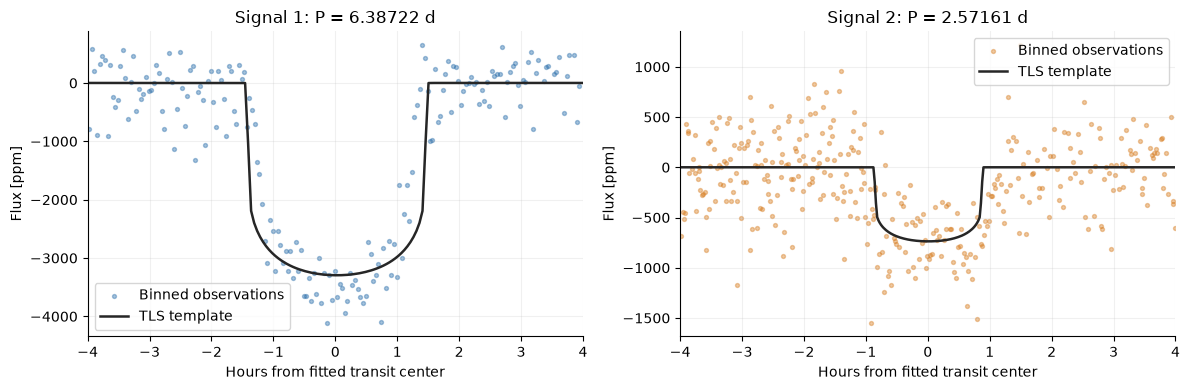

/home/AMD/absheikh/exoplanets/.venv/lib/python3.12/site-packages/transitleastsquares/grid.py:196: UserWarning: period_grid defaults to R_star=1 and M_star=1 as given density yielded grid with too few values
  warnings.warn(


Expanded first and second searches agree with common.two_pass.


/home/AMD/absheikh/exoplanets/.venv/lib/python3.12/site-packages/transitleastsquares/grid.py:196: UserWarning: period_grid defaults to R_star=1 and M_star=1 as given density yielded grid with too few values
  warnings.warn(


In [11]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for axis, tt, ff, result, number, color in zip(ax, [tm, t2m], [ym, y2m], [fine1, final2], [1, 2], COLORS[:2]):
    ph = phase_offset(tt, result.period, result.T0) * 24
    zoom = abs(ph) < 4
    axis.scatter(ph[zoom], ppm(ff[zoom]), s=8, alpha=.4, color=color, label='Binned observations')
    model_ph = (result.model_folded_phase - .5) * result.period * 24
    axis.plot(model_ph, ppm(result.model_folded_model), color='0.15', lw=1.8, label='TLS template')
    axis.set(xlim=(-4, 4), xlabel='Hours from fitted transit center', ylabel='Flux [ppm]',
             title=f'Signal {number}: P = {result.period:.5f} d')
    axis.legend()
show(fig, '09_two_folded_signals')

# Re-run the public two_pass helper to verify the expanded mechanism reproduces it.
for curve, expected_wide, expected_fine in [(lc, wide1, fine1), (remaining, wide2, fine2)]:
    helper_wide, helper_fine = common.two_pass(curve, star, CONFIG)
    np.testing.assert_allclose([helper_wide.period, helper_wide.SDE],
                               [expected_wide.period, expected_wide.SDE], rtol=1e-9)
    assert (helper_fine is None) == (expected_fine is None)
    if helper_fine is not None:
        np.testing.assert_allclose([helper_fine.period, helper_fine.T0, helper_fine.duration, helper_fine.depth],
                                  [expected_fine.period, expected_fine.T0, expected_fine.duration, expected_fine.depth], rtol=1e-9)
print('Expanded first and second searches agree with common.two_pass.')

## 7. A strong periodogram is only the start: inspect the events

The 100-star alternative benchmark scores SDE and catalog-period recovery; it **does not veto detections using the following checks**. The dataset builder does call `tess_hunt.search.vet_signal`, using the original project's separate preprocessing for measurements and centroid residuals. We demonstrate that measurement path on this same star.

| Measurement | Mechanism / reason to inspect it |
|---|---|
| Observed events | Count sufficiently sampled events, rather than assuming every predicted transit was observed |
| Individually supported events | Central-half dip versus nearby baseline; require local SNR ≥ 3 |
| Pink SNR | Increase the depth error using out-of-transit variation averaged on a transit-duration timescale |
| Odd/even difference | Alternating depths can suggest an eclipsing binary or a period alias |
| Secondary eclipse | Inspect the phase opposite the primary dip |
| Centroid shift | Movement during dips can indicate light from a neighboring source; inspect pixels |

The flags are heuristic prompts for review. In the plots below, the event depth uses the central half of each transit, whereas TLS reports a fitted template-bottom depth; these measurements need not agree numerically.

,depth,depth_ppm,depth_error,depth_snr,pink_snr,observed_transits,significant_events,odd_even_sigma,secondary_snr,centroid_snr,flags
Signal 1,0.002554,2554.331312,0.000042,61.027819,34.523894,4,4,2.706368,-1.504313,6.190585,[centroid_shift_requires_pixel_review]
Signal 2,0.000675,674.526294,0.000039,17.270826,11.193785,8,6,0.926973,2.097943,2.014520,[]


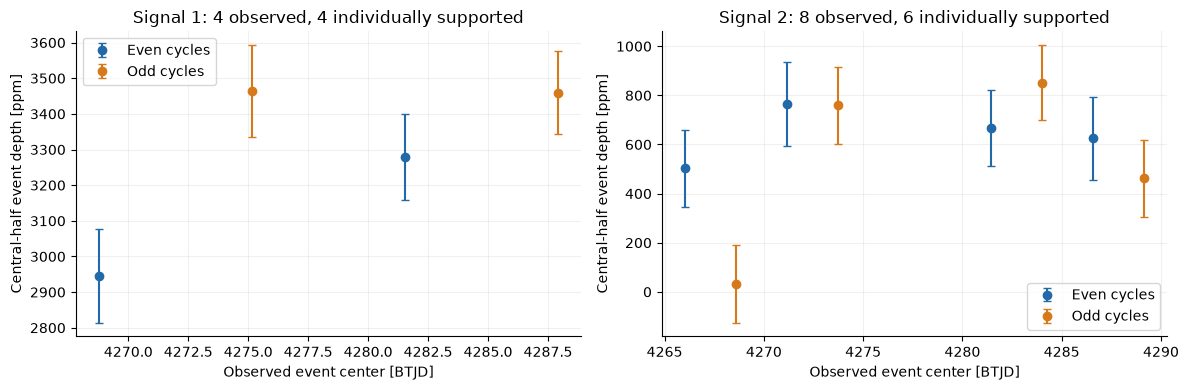

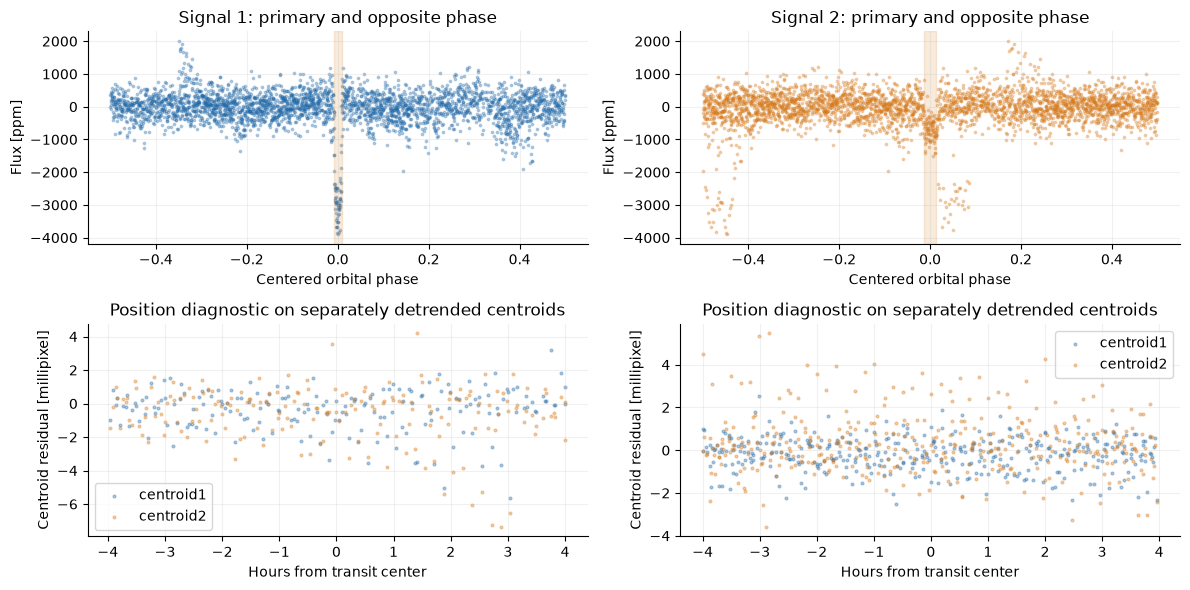

In [12]:
vet_data, vet_info = preprocess(path, CONFIG)
vets = [vet_signal(vet_data, r.period, r.T0, r.duration) for r in [fine1, final2]]
vet_table = pd.DataFrame([{k: v for k, v in vet.items() if k != 'events'} for vet in vets],
                         index=['Signal 1', 'Signal 2'])
display(vet_table)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for axis, vet, number in zip(ax, vets, [1, 2]):
    events = pd.DataFrame(vet['events'])
    for parity, label, color in [(0, 'Even cycles', COLORS[0]), (1, 'Odd cycles', COLORS[1])]:
        g = events[events.cycle.mod(2).eq(parity)]
        axis.errorbar(g.epoch_btjd, g.depth * 1e6, yerr=g.depth_error * 1e6,
                      fmt='o', capsize=3, color=color, label=label)
    axis.set(xlabel='Observed event center [BTJD]', ylabel='Central-half event depth [ppm]',
             title=f"Signal {number}: {vet['observed_transits']} observed, {vet['significant_events']} individually supported")
    axis.legend()
show(fig, '10_individual_events')

fig, ax = plt.subplots(2, 2, figsize=(12, 6))
for column, result in enumerate([fine1, final2]):
    ph = phase_offset(vet_data['time'], result.period, result.T0) / result.period
    ax[0, column].scatter(ph, ppm(vet_data['flux']), s=3, alpha=.3, color=COLORS[column])
    ax[0, column].set(xlabel='Centered orbital phase', ylabel='Flux [ppm]', title=f'Signal {column + 1}: primary and opposite phase')
    ax[0, column].axvspan(-result.duration / result.period / 2, result.duration / result.period / 2, color=COLORS[1], alpha=.15)
    ph_h = ph * result.period * 24
    near = abs(ph_h) < 4
    for name, color in [('centroid1', COLORS[0]), ('centroid2', COLORS[1])]:
        ax[1, column].scatter(ph_h[near], vet_data[name][near] * 1000, s=4, alpha=.35, color=color, label=name)
    ax[1, column].set(xlabel='Hours from transit center', ylabel='Centroid residual [millipixel]', title='Position diagnostic on separately detrended centroids')
    ax[1, column].legend()
show(fig, '11_secondary_and_centroid_checks')

## 8. Only now: compare with the planet catalog and the saved benchmark

The scoring helper calls a period match **`exact`** when the relative difference is below 1%; this label means within tolerance, not numerical equality. Half/double-period matches are separate. Epoch consistency and uncertainties need further checking before assigning a planet identity. A match is recovery of catalog period information, not independent confirmation of planetary nature.

The notebook checks its final parameters against the committed benchmark CSV, while showing the residual differences rather than assuming a historical run is bit-identical across machines and library versions.

In [13]:
known = pd.read_csv(ROOT / 'data/benchmark/known_planets.csv')
planets = known[known.tic.eq(TIC) & known.tran_flag.eq(1)
                & known.pl_orbper.between(CONFIG['period_min_days'], CONFIG['period_max_days'])]
catalog_rows = []
for number, result in enumerate([fine1, final2], 1):
    for planet in planets.itertuples():
        epoch_offset = (phase_offset([result.T0], planet.pl_orbper, planet.pl_tranmid - 2457000)[0]
                        if np.isfinite(planet.pl_tranmid) else np.nan)
        catalog_rows.append({'signal': number, 'catalog_name': planet.pl_name,
                             'catalog_period_days': planet.pl_orbper, 'fitted_period_days': result.period,
                             'period_difference_pct': 100 * (result.period / planet.pl_orbper - 1),
                             'relation': common.relation(result.period, planet.pl_orbper),
                             'nearest_catalog_epoch_offset_hours': epoch_offset * 24})
catalog_comparison = pd.DataFrame(catalog_rows)
display(catalog_comparison)
display(Markdown('**Inspect epoch offsets as well as period matches.** These offsets do not propagate catalog ephemeris uncertainty. A large offset is a reason to check published timing, time conventions and other sectors.'))

saved = pd.read_csv(common.OUT_DIR / 'benchmark_100.csv').set_index('tic').loc[TIC]
comparison = []
for prefix, result, wide in [('', fine1, wide1), ('s2_', final2, wide2)]:
    comparison.append({'signal': 1 if not prefix else 2,
                       'saved_period_days': saved[prefix + 'period'], 'rerun_period_days': result.period,
                       'difference_seconds': (result.period - saved[prefix + 'period']) * 86400,
                       'saved_wide_SDE': saved[prefix + 'sde'], 'rerun_wide_SDE': wide.SDE,
                       'saved_depth_ppm': saved[prefix + 'depth'] * 1e6,
                       'rerun_depth_ppm': (1 - result.depth) * 1e6})
display(pd.DataFrame(comparison))


,signal,catalog_name,catalog_period_days,fitted_period_days,period_difference_pct,relation,nearest_catalog_epoch_offset_hours
0,1,TOI-880 c,6.38727,6.387223,-0.000736,exact,0.041640
1,1,TOI-880.02,2.57571,6.387223,147.979133,None,18.173342
2,2,TOI-880 c,6.38727,2.571609,-59.738531,None,-65.924597
3,2,TOI-880.02,2.57571,2.571609,-0.159224,exact,14.024145


**Inspect epoch offsets as well as period matches.** These offsets do not propagate catalog ephemeris uncertainty. A large offset is a reason to check published timing, time conventions and other sectors.

,signal,saved_period_days,rerun_period_days,difference_seconds,saved_wide_SDE,rerun_wide_SDE,saved_depth_ppm,rerun_depth_ppm
0,1,6.387223,6.387223,0.0,17.620148,17.620148,3295.436967,3295.436967
1,2,2.571609,2.571609,0.0,16.254690,16.254690,737.288775,737.288775


### Collect the one-star result before zooming back out

The input was one star-sector row. The output contains two detected **signal patterns**, each with a period, depth and multiple observed events. This table records the freshly recomputed case, rather than summarizing all stars yet.

Keep three questions separate: does wide TLS pass its threshold, does the period match the catalog, and do the event measurements raise flags? The benchmark's recovery score uses the first two questions; the flags add reasons for review and do not veto that benchmark score.

In [14]:
case_rows = []
for number, result, wide, vet in zip([1, 2], [fine1, final2], [wide1, wide2], vets):
    matched = catalog_comparison[catalog_comparison.signal.eq(number)
                                 & catalog_comparison.relation.eq('exact')]
    case_rows.append({'tic': TIC, 'star': target['hostname'], 'sector': target['sector'],
                      'signal': number, 'period_days': float(result.period),
                      'wide_SDE': float(wide.SDE), 'wide_threshold_pass': bool(wide.SDE >= common.MIN_SDE),
                      'TLS_depth_ppm': float((1 - result.depth) * 1e6),
                      'observed_events': vet['observed_transits'],
                      'matched_catalog_names': ', '.join(matched.catalog_name),
                      'catalog_epoch_offset_hours': (matched.nearest_catalog_epoch_offset_hours.iloc[0]
                                                      if len(matched) else np.nan),
                      'measurement_flags': '; '.join(vet['flags']) or 'none'})
case_result = pd.DataFrame(case_rows)
display(case_result)

# Put only this recomputed case into an in-memory copy of the saved 100-star results.
# The committed CSV remains unchanged; the other 99 stars retain their saved outputs.
benchmark_view = snapshot_benchmark.copy()
case_index = benchmark_view.index[benchmark_view.tic.eq(TIC)][0]
for prefix, result, wide, number in [('', fine1, wide1, 1), ('s2_', final2, wide2, 2)]:
    benchmark_view.loc[case_index, prefix + 'period'] = float(result.period)
    benchmark_view.loc[case_index, prefix + 'sde'] = float(wide.SDE)
    benchmark_view.loc[case_index, prefix + 'depth'] = float(1 - result.depth)
    benchmark_view.loc[case_index, prefix + 'duration_h'] = float(result.duration * 24)
    rels = [common.relation(result.period, p) for p in planets.pl_orbper]
    match = ('exact' if 'exact' in rels else next((r for r in rels if r), None))
    benchmark_view.loc[case_index, prefix + 'match'] = match if wide.SDE >= common.MIN_SDE else None
benchmark_view['detected'] = benchmark_view.sde.ge(common.MIN_SDE) | benchmark_view.s2_sde.ge(common.MIN_SDE)
benchmark_view['first_exact'] = benchmark_view.sde.ge(common.MIN_SDE) & benchmark_view.match.eq('exact')
benchmark_view['either_exact'] = (benchmark_view.first_exact
                                | (benchmark_view.s2_sde.ge(common.MIN_SDE) & benchmark_view.s2_match.eq('exact')))
assert len(benchmark_view) == 100 and benchmark_view.tic.is_unique
print('The one-star result is now back in an in-memory table of 100 stars. No source CSV was overwritten.')

,tic,star,sector,signal,period_days,wide_SDE,wide_threshold_pass,TLS_depth_ppm,observed_events,matched_catalog_names,catalog_epoch_offset_hours,measurement_flags
0,34077285,TOI-880,107,1,6.387223,17.620148,True,3295.436967,4,TOI-880 c,0.041640,centroid_shift_requires_pixel_review
1,34077285,TOI-880,107,2,2.571609,16.254690,True,737.288775,8,TOI-880.02,14.024145,none


The one-star result is now back in an in-memory table of 100 stars. No source CSV was overwritten.


## Zoom out again: what happened across the 100-star benchmark?

The following aggregate uses **99 saved stars + the freshly recomputed TOI-880 row**. It is not a new full benchmark run. Each dot is one star; stars may have zero, one or two above-threshold signals. The highlighted dot is the same entry whose original flux we just inspected.

Known transiting hosts are scored by period recovery; comparison stars have no cataloged transiting planet. Signals on comparison stars are **flags for investigation**, not proven false positives. A non-recovery can reflect insufficient data, noise or the chosen search range.

,cohort,stars,question,positive outcome,other outcome
0,Known transiting hosts,60,"Catalog-period recovery, either signal",44,16
1,Comparison hosts,40,Any wide-search SDE >= 7,14,26


,tic,hostname,period,sde,s2_period,s2_sde,detected,first_exact,either_exact
7,34077285,TOI-880,6.387223,17.620148,2.571609,16.25469,True,True,True


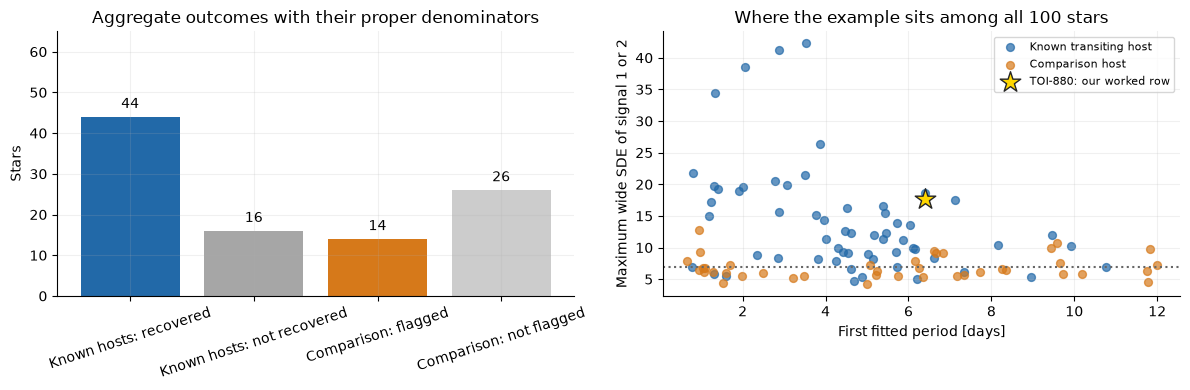

,hosts,first_signal,either_signal,repo_first_TLS
radius_bin,,,,
giant,20,19,19,19
medium,20,15,15,11
small,20,7,10,3


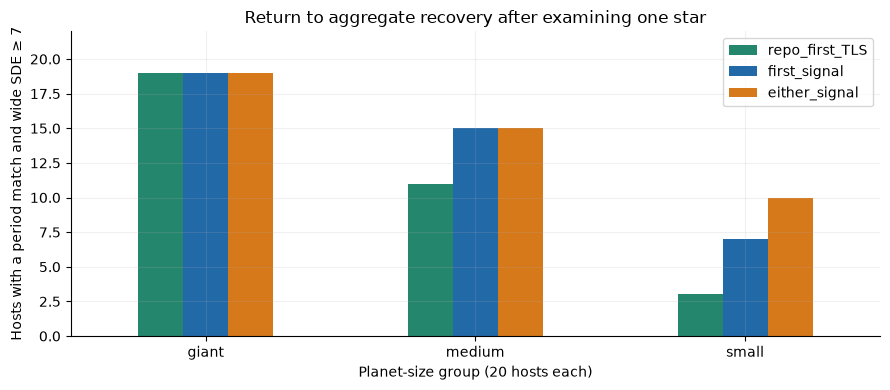

In [15]:
positive = benchmark_view[benchmark_view.catalog_group.eq('known_transiting_host')]
comparison_stars = benchmark_view[benchmark_view.catalog_group.eq('no_cataloged_transiting_planet')]
aggregate_benchmark = pd.DataFrame([
    {'cohort': 'Known transiting hosts', 'stars': len(positive),
     'question': 'Catalog-period recovery, either signal', 'positive outcome': int(positive.either_exact.sum()),
     'other outcome': int((~positive.either_exact).sum())},
    {'cohort': 'Comparison hosts', 'stars': len(comparison_stars),
     'question': 'Any wide-search SDE >= 7', 'positive outcome': int(comparison_stars.detected.sum()),
     'other outcome': int((~comparison_stars.detected).sum())},
])
display(aggregate_benchmark)
display(benchmark_view.loc[[case_index], ['tic', 'hostname', 'period', 'sde', 's2_period',
                                        's2_sde', 'detected', 'first_exact', 'either_exact']])

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
bars = ax[0].bar(['Known hosts: recovered', 'Known hosts: not recovered',
                  'Comparison: flagged', 'Comparison: not flagged'],
                 [positive.either_exact.sum(), (~positive.either_exact).sum(),
                  comparison_stars.detected.sum(), (~comparison_stars.detected).sum()],
                 color=[COLORS[0], '0.65', COLORS[1], '0.8'])
ax[0].bar_label(bars, padding=4, fmt='%.0f')
ax[0].set(ylabel='Stars', title='Aggregate outcomes with their proper denominators', ylim=(0, 65))
ax[0].tick_params(axis='x', rotation=18)
for g, color, label in [(positive, COLORS[0], 'Known transiting host'),
                         (comparison_stars, COLORS[1], 'Comparison host')]:
    peak = g[['sde', 's2_sde']].max(axis=1)
    ax[1].scatter(g.period, peak, s=32, alpha=.7, color=color, label=label)
case_peak = benchmark_view.loc[case_index, ['sde', 's2_sde']].max()
ax[1].scatter([fine1.period], [case_peak], s=240, marker='*', facecolor='gold',
              edgecolor='0.15', zorder=5, label='TOI-880: our worked row')
ax[1].axhline(common.MIN_SDE, color='0.4', ls=':')
ax[1].set(xlabel='First fitted period [days]', ylabel='Maximum wide SDE of signal 1 or 2',
          title='Where the example sits among all 100 stars')
ax[1].legend(fontsize=8)
show(fig, '12a_zoom_out_benchmark')

# Preserve the original size-stratified comparison, now placed after the worked case.
hosts = positive.merge(snapshot_hosts[['tic', 'repo_tls_exact']], on='tic', validate='one_to_one')
recovery = hosts.groupby('radius_bin').agg(hosts=('tic', 'size'), first_signal=('first_exact', 'sum'),
                                          either_signal=('either_exact', 'sum'), repo_first_TLS=('repo_tls_exact', 'sum'))
display(recovery)
fig, ax = plt.subplots(figsize=(9, 4))
recovery[['repo_first_TLS', 'first_signal', 'either_signal']].plot.bar(ax=ax, color=[COLORS[2], COLORS[0], COLORS[1]])
ax.set(ylabel='Hosts with a period match and wide SDE ≥ 7', xlabel='Planet-size group (20 hosts each)',
       title='Return to aggregate recovery after examining one star', ylim=(0, 22))
ax.tick_params(axis='x', rotation=0)
show(fig, '12_benchmark_recovery')

## 9. Return to the larger collection: how its search differs

We now switch back to the larger collection from the opening census. The following mechanisms produced its saved signal table; we do not rerun its raw searches here.

`02_build_dataset.py` uses up to **eight sectors** per star: the two largest runs of up to four consecutive sectors, with recency breaking ties. Each run is searched twice over 0.5–30 d, capped at half its span. After the first search it hides a total width of `max(2 * duration, 3 hours)` around every predicted event.

Candidates from different runs are merged when their periods agree within 1%, including half/double aliases. The three candidates appearing in the most distinct runs are retained, with strength breaking ties. Period and epoch are refined on all retained sectors within ±0.5% of each selected peak; **duration comes from the run search**, avoiding reliance on the long-gap duration estimate.

This path uses the initial unmasked cleaning recipe. It **does not call `common.two_pass`** and does not do the transit-masked re-flattening illustrated above. Keeping the paths distinct matters when interpreting the classifier's inputs.

Here is an explicitly illustrative observing schedule passed through the actual grouping/capping functions; it contains no fabricated flux measurements.

,run,sectors,retained_by_cap
0,1,"[1, 2, 3, 4]",True
1,2,[5],False
2,3,"[8, 9, 10]",False
3,4,"[20, 21, 22, 23]",True


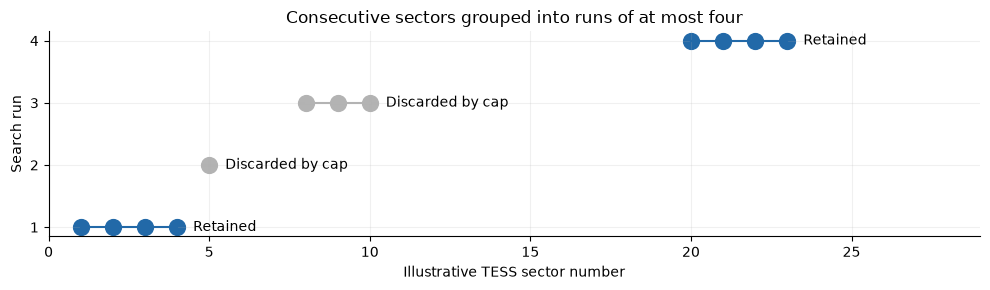

In [16]:
illustrative_sectors = [1, 2, 3, 4, 5, 8, 9, 10, 20, 21, 22, 23]
illustrative_paths = [f'illustration-s{s:04d}-target-lc.fits' for s in illustrative_sectors]
groups = dataset.chunks(illustrative_paths)
retained = set(dataset.capped(illustrative_paths))
display(pd.DataFrame([{'run': i + 1, 'sectors': [int(p.split('-s')[1][:4]) for p in group],
                       'retained_by_cap': all(p in retained for p in group)}
                      for i, group in enumerate(groups)]))
fig, ax = plt.subplots(figsize=(10, 3))
for i, group in enumerate(groups):
    sectors = [int(p.split('-s')[1][:4]) for p in group]
    selected = all(p in retained for p in group)
    ax.scatter(sectors, [i + 1] * len(sectors), s=130, color=COLORS[0] if selected else '0.7')
    if len(sectors) > 1:
        ax.plot(sectors, [i + 1] * len(sectors), color=COLORS[0] if selected else '0.7')
    ax.text(max(sectors) + .5, i + 1, 'Retained' if selected else 'Discarded by cap', va='center')
ax.set(xlabel='Illustrative TESS sector number', ylabel='Search run', yticks=range(1, len(groups) + 1),
       title='Consecutive sectors grouped into runs of at most four', xlim=(0, 29))
show(fig, '13_sector_grouping')

## 10. From detected signals to training labels

The saved TOI snapshot supplies TFOP Working Group dispositions: **CP/KP** = confirmed/known planet; **FP/FA** = false positive/false alarm; **PC** = unresolved candidate. These are catalog labels, distinct from this search's own conclusions.

Stars are sampled with a single class among their decided TOIs; benchmark stars are excluded. A signal gets a TOI disposition only after its discovered period matches that star's TOI within 1%. Period-only matching can still misassociate a signal, and confirmed hosts can contain additional uncataloged signals.

The classifier keeps:

| Detected-signal category | Classifier treatment |
|---|---|
| Matches CP/KP | Planet label |
| Matches FP/FA | False label |
| Unmatched on a false-only star, no half/double TOI match | Assumed false label |
| Unmatched on a planet star | Excluded: could be an unlisted planet |
| Unmatched half/double alias, or PC match | Excluded |

The unmatched false-star examples are assumptions, not individually adjudicated false alarms. The **hard subset** includes only CP/KP and FP/FA matches, leaving those easier unmatched examples out of the evaluation.

load: dropped 18 rows ({'FP': 13, 'FA': 4, 'KP': 1}) of 18 stars with no light curve of their own


detected_signals
star_class label                  
false      APC                   1
           FA                   18
           FP                  613
           PC                    8
           none               1600
planet     CP                  572
           KP                  540
           PC                   14
           none               2188

,quantity,count
0,Sampled stars,2454
1,Stars with usable sectors,2204
2,Detected signals,5554
3,Retained classifier examples,1725
4,Planet examples,1111
5,Matched false examples,614
6,Assumed false unmatched examples,0
7,Hard-subset examples,1725


The benchmark stars, including TOI-880, are excluded from the classifier dataset.


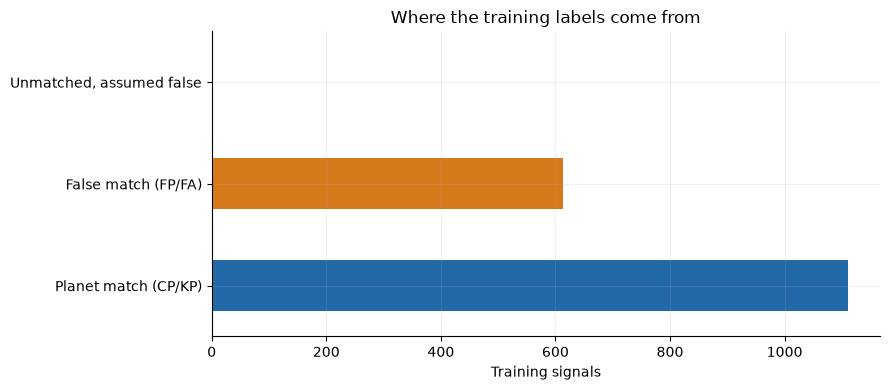

In [17]:
signals = pd.read_csv(common.OUT_DIR / 'dataset_signals.csv')
stars = pd.read_csv(common.OUT_DIR / 'dataset_stars.csv')
df = classifier.load().reset_index(drop=True)
display(signals.groupby(['star_class', 'label']).size().rename('detected_signals').to_frame())
display(pd.DataFrame({'quantity': ['Sampled stars', 'Stars with usable sectors', 'Detected signals',
                                  'Retained classifier examples', 'Planet examples', 'Matched false examples',
                                  'Assumed false unmatched examples', 'Hard-subset examples'],
                      'count': [len(stars), stars.sectors.gt(0).sum(), len(signals), len(df),
                                df.y.sum(), df.label.isin(['FP', 'FA']).sum(),
                                df.label.eq('none').sum(), df.hard.sum()]}))
benchmark_tics = set(targets.tic)
assert not benchmark_tics.intersection(set(df.tic))
print('The benchmark stars, including TOI-880, are excluded from the classifier dataset.')

fig, ax = plt.subplots(figsize=(9, 4))
counts = pd.Series({'Planet match (CP/KP)': int(df.y.sum()),
                    'False match (FP/FA)': int(df.label.isin(['FP', 'FA']).sum()),
                    'Unmatched, assumed false': int(df.label.eq('none').sum())})
counts.plot.barh(ax=ax, color=[COLORS[0], COLORS[1], COLORS[3]])
ax.set(xlabel='Training signals', title='Where the training labels come from')
show(fig, '14_training_labels')

### Zoom in on one actual classifier-dataset entry

For the feature-to-score part, select **TIC 459762279, signal 1**, which matches **TOI 5573.01 (CP)** in the saved run. This is a real row from the larger collection, separate from TOI-880. We also display signal 2 from the same star: it was unmatched and therefore excluded from classifier training. One star producing two signals does not imply two training examples.

The flux-to-signal processing for this star was done in the saved dataset run. Here we begin at its local measured-feature row; no raw flux or fresh TLS result is fabricated. The classifier score for the retained signal will be recomputed below using a model that never trained on this star.

In [18]:
TRAINING_TIC, TRAINING_SIGNAL = 459762279, 1
training_star = stars[stars.tic.eq(TRAINING_TIC)]
training_raw_signals = signals[signals.tic.eq(TRAINING_TIC)]
training_entry = df[df.tic.eq(TRAINING_TIC) & df.signal.eq(TRAINING_SIGNAL)]
assert len(training_star) == 1 and len(training_entry) == 1
assert TRAINING_TIC not in set(targets.tic)
display(training_star[['tic', 'star_class', 'sectors', 'chunks', 'span_days', 'recovered']])
display(training_raw_signals[['tic', 'signal', 'period', 'duration_h', 'best_chunk_sde',
                              'depth_ppm', 'pink_snr', 'observed_transits', 'label', 'flags']])
display(training_entry[['tic', 'signal', 'label', 'y', 'hard', 'rules_pass']])
print('Selected one eligible signal from the table; its unmatched companion is not used as a training example.')

,tic,star_class,sectors,chunks,span_days,recovered
56,459762279,planet,1.0,1.0,26.498109,True


,tic,signal,period,duration_h,best_chunk_sde,depth_ppm,pink_snr,observed_transits,label,flags
2,459762279,1,8.794562,1.758026,19.983612,11764.073045,13.805924,3,CP,NaN
3,459762279,2,6.356174,2.509089,8.643677,2478.059600,3.304312,3,none,fewer_than_two_individually_supported_events


,tic,signal,label,y,hard,rules_pass
1,459762279,1,CP,1,True,1


Selected one eligible signal from the table; its unmatched companion is not used as a training example.


## 11. Features: turn measurements into a signal description

The classifier is `HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, random_state=0)`. Its inputs are measured properties of each dip pattern, not a flux image or the TOI label itself.

Planet stars tend to have more observations. The code therefore transforms counts into rates and divides signal strengths by $\sqrt{N_{\rm observed\ events}}$. These are heuristic transformations intended to reduce dependence on data volume; **they do not guarantee removal of that dependence**, and wide-chunk SDE is not a direct per-event SNR. Data-amount-only and within-sector-count comparisons probe this potential shortcut.

In [19]:
feature_explanations = {
    'period': 'Fitted repeat period [days]',
    'duration_h': 'Run-search transit duration [hours]',
    'depth_ppm': 'Vetted flux decrement [ppm]',
    'sde_per_transit': 'Best run SDE / sqrt(observed events)',
    'depth_snr_per_transit': 'Formal depth SNR / sqrt(observed events)',
    'pink_snr_per_transit': 'Noise-aware depth SNR / sqrt(observed events)',
    'odd_even_sigma': 'Alternating-event depth difference / error',
    'secondary_snr': 'Opposite-phase dip / noise-aware error',
    'centroid_snr': 'Largest position shift / estimated error',
    'transits_per_sector': 'Observed events / retained sectors',
    'significant_event_fraction': 'Individually significant events / observed events',
    'chunk_fraction': 'Distinct runs finding the candidate / retained runs',
}
display(pd.Series(feature_explanations).rename('mechanism').to_frame().loc[classifier.DIP_FEATURES])
raw_entry = training_raw_signals[training_raw_signals.signal.eq(TRAINING_SIGNAL)].iloc[0]
prepared_entry = training_entry.iloc[0]
feature_trace = pd.DataFrame([
    {'feature': 'transits_per_sector', 'calculation': 'observed events / sectors',
     'from this entry': raw_entry.observed_transits / prepared_entry.sectors,
     'actual classifier value': prepared_entry.transits_per_sector},
    {'feature': 'significant_event_fraction', 'calculation': 'significant events / observed events',
     'from this entry': raw_entry.significant_events / raw_entry.observed_transits,
     'actual classifier value': prepared_entry.significant_event_fraction},
    {'feature': 'chunk_fraction', 'calculation': 'runs finding signal / retained runs',
     'from this entry': raw_entry.n_chunks_found / prepared_entry.chunks,
     'actual classifier value': prepared_entry.chunk_fraction},
    {'feature': 'sde_per_transit', 'calculation': 'best-run SDE / sqrt(observed events)',
     'from this entry': raw_entry.best_chunk_sde / np.sqrt(max(1, raw_entry.observed_transits)),
     'actual classifier value': prepared_entry.sde_per_transit},
    {'feature': 'pink_snr_per_transit', 'calculation': 'pink SNR / sqrt(observed events)',
     'from this entry': raw_entry.pink_snr / np.sqrt(max(1, raw_entry.observed_transits)),
     'actual classifier value': prepared_entry.pink_snr_per_transit},
])
np.testing.assert_allclose(feature_trace['from this entry'], feature_trace['actual classifier value'])
display(feature_trace)
display(training_entry[['tic', 'signal', 'label', 'y', 'hard', *classifier.DIP_FEATURES]])
display(df.groupby('y')[['sectors', 'sectors_available', 'span_days', 'chunks']].median()
        .rename(index={0: 'False', 1: 'Planet'}))

,mechanism
period,Fitted repeat period [days]
duration_h,Run-search transit duration [hours]
depth_ppm,Vetted flux decrement [ppm]
sde_per_transit,Best run SDE / sqrt(observed events)
depth_snr_per_transit,Formal depth SNR / sqrt(observed events)
pink_snr_per_transit,Noise-aware depth SNR / sqrt(observed events)
odd_even_sigma,Alternating-event depth difference / error
secondary_snr,Opposite-phase dip / noise-aware error
centroid_snr,Largest position shift / estimated error
transits_per_sector,Observed events / retained sectors


,feature,calculation,from this entry,actual classifier value
0,transits_per_sector,observed events / sectors,3.000000,3.000000
1,significant_event_fraction,significant events / observed events,1.000000,1.000000
2,chunk_fraction,runs finding signal / retained runs,1.000000,1.000000
3,sde_per_transit,best-run SDE / sqrt(observed events),11.537544,11.537544
4,pink_snr_per_transit,pink SNR / sqrt(observed events),7.970854,7.970854


,tic,signal,label,y,hard,period,duration_h,depth_ppm,sde_per_transit,depth_snr_per_transit,pink_snr_per_transit,odd_even_sigma,secondary_snr,centroid_snr,transits_per_sector,significant_event_fraction,chunk_fraction
1,459762279,1,CP,1,True,8.794562,1.758026,11764.073045,11.537544,7.970854,7.970854,1.142769,-0.864677,3.117676,3.0,1.0,1.0


,sectors,sectors_available,span_days,chunks
y,,,,
False,2.0,2.5,241.395678,2.0
Planet,3.0,5.0,757.421010,2.0


## 12. Grouped validation: do not train and test on the same star

`StratifiedGroupKFold` makes five folds grouped by **TIC**, so every signal from one star stays together. Each score below comes from a model that did not train on that star. We rerun the actual classifier helper rather than presenting committed scores as a fresh computation. This evaluates ranking and screening in the selected sample; the returned `predict_proba` values are **uncalibrated model scores**, not validated astrophysical planet probabilities.

The saved score CSV does not contain the fold assignments. We reconstruct the deterministic folds and explicitly check that their training and test stars never overlap.

,fold,training_stars,held_out_stars,held_out_signals,overlapping_stars
0,0,1330,333,345,0
1,1,1330,333,345,0
2,2,1331,332,345,0
3,3,1331,332,345,0
4,4,1330,333,345,0


Actual grouped cross-validation helpers completed in 7.7 s.
Mean absolute difference from saved scores: 3.742653721786864e-17


,subset,features,ROC_AUC,average_precision
0,All retained signals,Dip features,0.858359,0.911921
1,All retained signals,Data amount only,0.793751,0.853232
2,Catalog-matched hard subset,Dip features,0.858359,0.911921
3,Catalog-matched hard subset,Data amount only,0.793751,0.853232


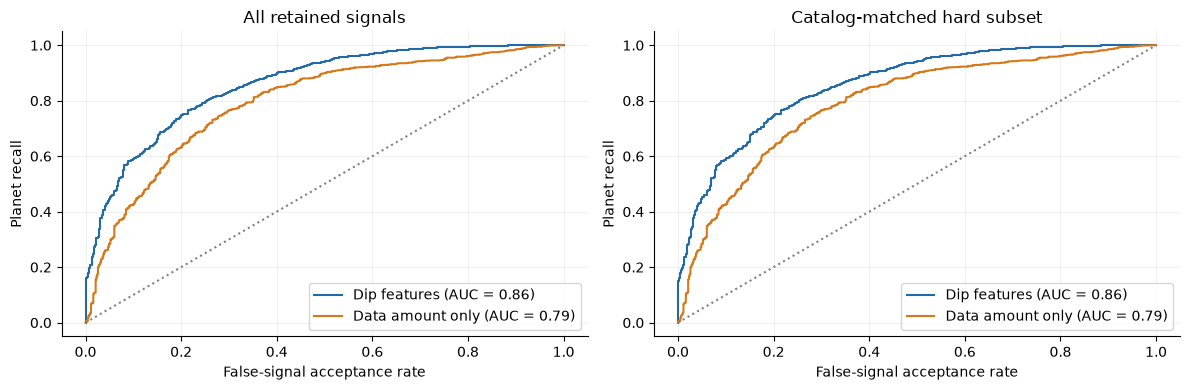

In [20]:
from sklearn.metrics import ConfusionMatrixDisplay, roc_curve, roc_auc_score, average_precision_score
from sklearn.model_selection import StratifiedGroupKFold

splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=classifier.SEED)
fold_rows = []
for k, (train, test) in enumerate(splitter.split(df, df.y, groups=df.tic)):
    train_stars, test_stars = set(df.tic.iloc[train]), set(df.tic.iloc[test])
    assert not train_stars.intersection(test_stars)
    fold_rows.append({'fold': k, 'training_stars': len(train_stars), 'held_out_stars': len(test_stars),
                      'held_out_signals': len(test), 'overlapping_stars': 0})
display(pd.DataFrame(fold_rows))

start = time.perf_counter()
amount_scores, amount_folds, _ = classifier.cross_validate(df, classifier.AMOUNT_FEATURES)
scores, folds, importances = classifier.cross_validate(df, classifier.DIP_FEATURES)
print(f'Actual grouped cross-validation helpers completed in {time.perf_counter() - start:.1f} s.')
np.testing.assert_array_equal(folds, amount_folds)
scored = df.assign(planet_score=scores, fold=folds)

saved_scores = pd.read_csv(common.OUT_DIR / 'classifier_scores.csv')
saved_alignment = scored[['tic', 'signal', 'planet_score']].merge(
    saved_scores[['tic', 'signal', 'planet_score']], on=['tic', 'signal'],
    suffixes=('_rerun', '_saved'), validate='one_to_one')
assert len(saved_alignment) == len(scored)
print('Mean absolute difference from saved scores:',
      np.mean(abs(saved_alignment.planet_score_rerun - saved_alignment.planet_score_saved)))

ranking = []
for name, mask in [('All retained signals', np.ones(len(df), bool)), ('Catalog-matched hard subset', df.hard.values)]:
    for model_name, values in [('Dip features', scores), ('Data amount only', amount_scores)]:
        ranking.append({'subset': name, 'features': model_name,
                        'ROC_AUC': roc_auc_score(df.y[mask], values[mask]),
                        'average_precision': average_precision_score(df.y[mask], values[mask])})
display(pd.DataFrame(ranking))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for axis, mask, title in zip(ax, [np.ones(len(df), bool), df.hard.values], ['All retained signals', 'Catalog-matched hard subset']):
    for label, values, color in [('Dip features', scores, COLORS[0]), ('Data amount only', amount_scores, COLORS[1])]:
        fpr, tpr, _ = roc_curve(df.y[mask], values[mask])
        auc = roc_auc_score(df.y[mask], values[mask])
        axis.plot(fpr, tpr, label=f'{label} (AUC = {auc:.2f})', color=color)
    axis.plot([0, 1], [0, 1], ls=':', color='0.5')
    axis.set(title=title, xlabel='False-signal acceptance rate', ylabel='Planet recall')
    axis.legend()
show(fig, '15_grouped_validation')

### Get the selected entry's result from its held-out fold

The example row's features now enter a model trained on the other folds. We locate its fold, verify that its TIC was absent from that fold's training stars, and display the score alongside its known label and the fixed-rules result. **Known label**, **measured features**, and **model prediction** are separate columns.

In [21]:
entry_index = df.index[df.tic.eq(TRAINING_TIC) & df.signal.eq(TRAINING_SIGNAL)][0]
entry_fold = int(folds[entry_index])
all_splits = list(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=classifier.SEED)
                  .split(df, df.y, groups=df.tic))
train_indices, test_indices = all_splits[entry_fold]
assert entry_index in test_indices
assert TRAINING_TIC not in set(df.tic.iloc[train_indices])
classifier_entry_result = scored.loc[[entry_index], ['tic', 'signal', 'label', 'period',
                                                   'depth_ppm', 'pink_snr', 'rules_pass', 'planet_score', 'fold']].copy()
classifier_entry_result['score_above_0.5'] = classifier_entry_result.planet_score.gt(.5)
classifier_entry_result['known_catalog_class'] = 'planet (CP)'
display(classifier_entry_result)
print(f'TIC {TRAINING_TIC} was held out in fold {entry_fold}; no signals from this star were used to train its scoring model.')
print('This is an uncalibrated screening score; the CP label comes from the catalog, not from the classifier.')

,tic,signal,label,period,depth_ppm,pink_snr,rules_pass,planet_score,fold,score_above_0.5,known_catalog_class
1,459762279,1,CP,8.794562,11764.073045,13.805924,1,0.969733,3,True,planet (CP)


TIC 459762279 was held out in fold 3; no signals from this star were used to train its scoring model.
This is an uncalibrated screening score; the CP label comes from the catalog, not from the classifier.


## 13. Zoom out: aggregate classifier successes and failures

The selected entry is now one row in `scored`, alongside every other held-out classifier example. We return to the full collection to see whether its behavior is typical and where the approach fails.

At threshold 0.5, compare the classifier with the script's fixed rules: **best-run SDE ≥ 7, pink SNR ≥ 7.1, at least two observed events, and no warning flags**. These rules omit BLS agreement and differ from the original full pipeline's decision logic.

The hard subset below contains only catalog-labeled planet/false signals. Misses and false positives remain visible in the confusion matrices. The feature-importance plot shuffles one input at a time in held-out folds and measures the drop in average precision; it indicates model reliance, not physical causation.

,planet_recall,false_signals_accepted,accuracy
method,,,
"Classifier, score > 0.5",87.8%,36.6%,79.1%
Fixed rules,59.9%,29.8%,63.6%


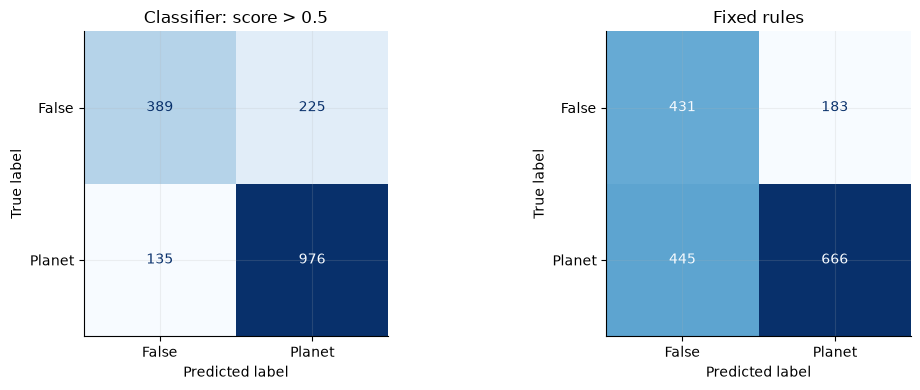

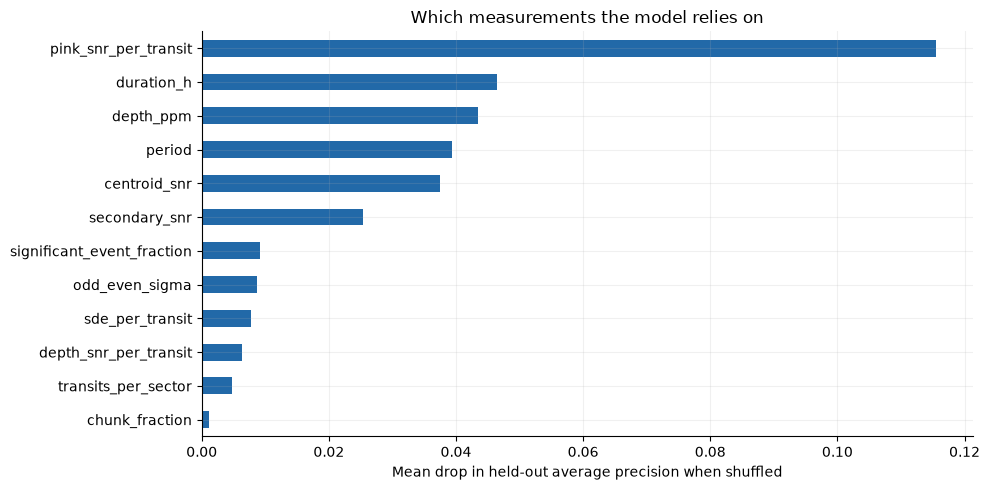

,case,tic,signal,label,planet_score,period,depth_ppm,pink_snr,odd_even_sigma,centroid_snr,flags
573,"Planet, low score",123482865,2,CP,0.003321,6.555845,2044.694953,21.450062,5.757387,10.401314,odd_even_depth_mismatch;centroid_shift_require...
175,"Planet, low score",387342052,1,CP,0.003369,3.541410,2300.724443,19.182658,19.035816,8.337961,odd_even_depth_mismatch;centroid_shift_require...
680,"Planet, low score",138644215,1,KP,0.003997,1.544958,2179.248451,15.481147,0.603706,6.072408,centroid_shift_requires_pixel_review
1720,"False signal, high score",235684392,1,FP,0.998364,21.791437,8399.861462,27.164668,0.381218,5.663023,centroid_shift_requires_pixel_review
1257,"False signal, high score",55748194,1,FA,0.998199,2.522819,17878.033584,91.790593,0.080687,6.678041,centroid_shift_requires_pixel_review
1684,"False signal, high score",169532369,1,FP,0.998066,3.603713,6473.642779,53.481052,0.747541,1.096533,NaN


In [22]:
hard = scored[scored.hard]
pred_model = hard.planet_score.gt(.5).astype(int)
pred_rules = hard.rules_pass.astype(int)
metrics = []
for name, pred in [('Classifier, score > 0.5', pred_model), ('Fixed rules', pred_rules)]:
    metrics.append({'method': name, 'planet_recall': pred[hard.y.eq(1)].mean(),
                    'false_signals_accepted': pred[hard.y.eq(0)].mean(),
                    'accuracy': pred.eq(hard.y).mean()})
display(pd.DataFrame(metrics).set_index('method').style.format('{:.1%}'))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for axis, pred, title in zip(ax, [pred_model, pred_rules], ['Classifier: score > 0.5', 'Fixed rules']):
    ConfusionMatrixDisplay.from_predictions(hard.y, pred, display_labels=['False', 'Planet'],
                                           ax=axis, colorbar=False, cmap='Blues')
    axis.set_title(title)
show(fig, '16_confusion_matrices')

fig, ax = plt.subplots(figsize=(10, 5))
pd.Series(importances, index=classifier.DIP_FEATURES).sort_values().plot.barh(ax=ax, color=COLORS[0])
ax.set(xlabel='Mean drop in held-out average precision when shuffled', title='Which measurements the model relies on')
show(fig, '17_feature_importance')

# Show actual held-out successes and mistakes; no score is assigned to TOI-880 here.
examples = pd.concat([
    hard[hard.y.eq(1)].nsmallest(3, 'planet_score').assign(case='Planet, low score'),
    hard[hard.y.eq(0)].nlargest(3, 'planet_score').assign(case='False signal, high score')])
display(examples[['case', 'tic', 'signal', 'label', 'planet_score', 'period',
                  'depth_ppm', 'pink_snr', 'odd_even_sigma', 'centroid_snr', 'flags']])

## 14. Compare sensitivity at a similar false-signal acceptance rate

The script also compares planet recall at the fixed rules' false-signal acceptance rate. It chooses a score threshold from each held-out fold's **false-labeled examples**. This is a retrospective ROC comparison, not a deployable threshold determined independently of the test data. A future deployed threshold needs a separate validation/calibration set.

The `±` below is the standard deviation over five folds, not a confidence interval. Comparisons by sector count are another diagnostic for data-volume dependence; they do not establish population-wide sensitivity.

In [23]:
mean, std = classifier.fold_stats(df, scores, folds, df.hard.values)
display(pd.DataFrame({'fold_mean': mean, 'fold_std': std}))
within_amount = []
for months, g in hard.groupby(pd.cut(hard.sectors, [0, 1, 2, 4, 8],
                                     labels=['1', '2', '3–4', '5–8']), observed=True):
    fake_scores = g.loc[g.y.eq(0), 'planet_score']
    fake_rate = g.loc[g.y.eq(0), 'rules_pass'].mean()
    if len(fake_scores) and g.y.eq(1).any():
        cutoff = np.quantile(fake_scores, 1 - fake_rate)
        within_amount.append({'retained_sectors': str(months), 'signals': len(g),
                              'rules_planet_recall': g.loc[g.y.eq(1), 'rules_pass'].mean(),
                              'model_planet_recall_at_matched_rate': g.loc[g.y.eq(1), 'planet_score'].gt(cutoff).mean(),
                              'rules_false_acceptance_rate': fake_rate})
display(pd.DataFrame(within_amount))

,fold_mean,fold_std
roc_auc,0.859684,0.010635
avg_precision,0.913427,0.010565
rules_planets_caught,0.599491,0.033798
rules_fakes_passed,0.298027,0.043847
model_planets_caught,0.833499,0.034050


,retained_sectors,signals,rules_planet_recall,model_planet_recall_at_matched_rate,rules_false_acceptance_rate
0,1,232,0.640449,0.808989,0.258741
1,2,527,0.550152,0.848024,0.292929
2,3–4,604,0.615385,0.841629,0.296296
3,5–8,362,0.621514,0.808765,0.360360


### Locate the single score within the entire scored dataset

A reassuring example is not sufficient evidence of a good pipeline. These distributions place the selected training signal among **all retained classifier examples** and the catalog-matched hard subset. Planet and false-signal scores overlap; the threshold trades recovered planets against accepted false signals.

The final census reconnects the end of the notebook to its opening: which stars had data, which signals were recorded, which examples were eligible, and how many pass the score threshold. Counts of accepted signals are not counts of newly discovered planets.

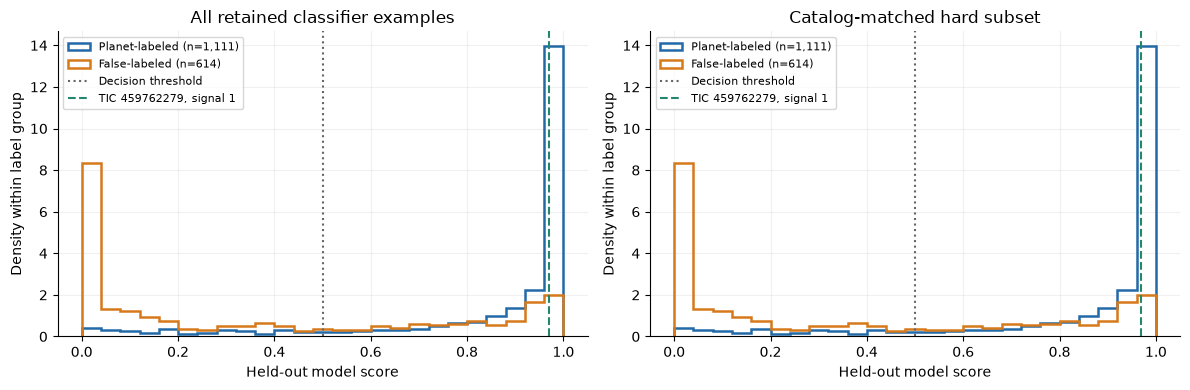

,stage,unit,count
0,Benchmark input stars,stars,100
1,Known benchmark hosts: catalog period recovered,stars / 60 known hosts,44
2,Larger collection: selected stars,stars,2454
3,Larger collection: stars with usable sectors,stars,2204
4,Signals recorded by the larger search,candidate signals,5554
5,Signals excluded by label eligibility,candidate signals,3829
6,Retained and scored with held-out models,classifier examples,1725
7,Hard subset evaluated separately,catalog-matched examples,1725
8,All examples with score > 0.5,accepted signals,1201
9,Hard subset: planets accepted,planet-labeled examples,976


Both worked entries reconnect to the same dataset census used at the start.


In [24]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharex=True)
for axis, table, title in zip(ax, [scored, scored[scored.hard]],
        ['All retained classifier examples', 'Catalog-matched hard subset']):
    for truth, color, label in [(1, COLORS[0], 'Planet-labeled'), (0, COLORS[1], 'False-labeled')]:
        values = table.loc[table.y.eq(truth), 'planet_score']
        axis.hist(values, bins=np.linspace(0, 1, 26), histtype='step', density=True,
                  lw=1.8, color=color, label=f'{label} (n={len(values):,})')
    axis.axvline(.5, color='0.4', ls=':', label='Decision threshold')
    axis.axvline(float(scored.loc[entry_index, 'planet_score']), color=COLORS[2], ls='--',
                 label=f'TIC {TRAINING_TIC}, signal {TRAINING_SIGNAL}')
    axis.set(xlabel='Held-out model score', ylabel='Density within label group', title=title)
    axis.legend(fontsize=8)
show(fig, '18_zoom_out_score_distribution')

final_census = pd.DataFrame([
    {'stage': 'Benchmark input stars', 'unit': 'stars', 'count': len(snapshot_targets)},
    {'stage': 'Known benchmark hosts: catalog period recovered', 'unit': 'stars / 60 known hosts',
     'count': int(positive.either_exact.sum())},
    {'stage': 'Larger collection: selected stars', 'unit': 'stars', 'count': len(stars)},
    {'stage': 'Larger collection: stars with usable sectors', 'unit': 'stars', 'count': int(stars.sectors.gt(0).sum())},
    {'stage': 'Signals recorded by the larger search', 'unit': 'candidate signals', 'count': len(signals)},
    {'stage': 'Signals excluded by label eligibility', 'unit': 'candidate signals', 'count': len(signals) - len(scored)},
    {'stage': 'Retained and scored with held-out models', 'unit': 'classifier examples', 'count': len(scored)},
    {'stage': 'Hard subset evaluated separately', 'unit': 'catalog-matched examples', 'count': int(scored.hard.sum())},
    {'stage': 'All examples with score > 0.5', 'unit': 'accepted signals', 'count': int(scored.planet_score.gt(.5).sum())},
    {'stage': 'Hard subset: planets accepted', 'unit': 'planet-labeled examples',
     'count': int((scored.hard & scored.y.eq(1) & scored.planet_score.gt(.5)).sum())},
    {'stage': 'Hard subset: false signals accepted', 'unit': 'false-labeled examples',
     'count': int((scored.hard & scored.y.eq(0) & scored.planet_score.gt(.5)).sum())},
])
display(final_census)

# Check that the zoomed entries are genuinely members of their aggregate result tables.
assert TIC in set(benchmark_view.tic)
assert ((scored.tic == TRAINING_TIC) & (scored.signal == TRAINING_SIGNAL)).sum() == 1
assert len(scored) == len(snapshot_scores)
assert len(signals) == len(snapshot_signals)
print('Both worked entries reconnect to the same dataset census used at the start.')

## What the full pipeline view establishes

We started with the saved collection, distinguished star rows from signal rows, and selected a real benchmark entry. TOI-880's flux was cleaned, searched, masked and searched again, with intermediate arrays and plots checked against `common.two_pass`. Its two signals were then returned to an in-memory 100-star result table; the aggregate combines that recomputed entry with 99 saved entries.

We next returned to the separate larger dataset, followed its labeling rules, and selected **TIC 459762279, signal 1** as an actual training example. Its saved measurements were transformed into features, its score was freshly computed in a fold that excluded its entire star, and the example was placed back among all 3,198 held-out classifier scores. No classifier score was invented for TOI-880, and no raw search was pretended for the larger dataset.

TOI-880's final periods are about **6.38722 d** and **2.57161 d**. Masked refinement changes the first fitted bottom depth from about **1,610 ppm** to **3,295 ppm**, without establishing an independent true depth. Its centroid warning and the second signal's roughly **14-hour catalog epoch offset** still require review. The classifier evaluation includes its misses and accepted false signals; a score supports prioritization, not independent planet confirmation.

All source CSVs remain unchanged. Figures are saved under the notebook's ignored diagnostic folder, outputs are embedded, and the provenance below records the source code, numerical environment and data snapshots used for the walkthrough.

In [25]:
import astropy
import scipy
import sklearn
import transitleastsquares as tls_package
provenance['versions'] = {'lightkurve': lk.__version__, 'numpy': np.__version__,
                          'pandas': pd.__version__, 'astropy': astropy.__version__,
                          'scipy': scipy.__version__, 'scikit-learn': sklearn.__version__,
                          'transitleastsquares': tls_package.__version__}
provenance['snapshot_sha256'] = {
    str(p.relative_to(ROOT)): hashlib.sha256(p.read_bytes()).hexdigest()
    for p in [ROOT / 'config/benchmark.json', ROOT / 'data/benchmark/targets.csv',
              ROOT / 'data/dataset/toi_labeled.csv',
              common.OUT_DIR / 'benchmark_100.csv', common.OUT_DIR / 'benchmark_100_hosts.csv',
              ROOT / 'data/benchmark/known_planets.csv',
              common.OUT_DIR / 'dataset_signals.csv', common.OUT_DIR / 'dataset_stars.csv',
              common.OUT_DIR / 'classifier_scores.csv']}
display(pd.Series(provenance['versions']).to_frame('version'))
display(provenance)
print(f'Walkthrough complete: {len(list(FIGURES.glob("*.png")))} diagnostic figures generated.')

,version
lightkurve,2.6.0
numpy,2.5.4
pandas,2.3.3
astropy,8.0.1
scipy,1.18.1
scikit-learn,1.9.1
transitleastsquares,2.0


{'git_commit': '06d7c328b45b54b6c97feb704bc9b1d74c500152',
 'python': '3.12.3',
 'source_sha256': {'common.py': 'f0638fd3fd9b29466d1c3d1a7966a44410cbb40cfce9435c555956647b7aae31',
  '01_benchmark.py': 'c616f837e8b00d807e895fd70e71ff506194464caeb3e89611a9375b683d20fe',
  '02_build_dataset.py': '5e01a60ff18d7a793f5200907e5f09586c40e036852997281222b47b5cca3e61',
  '03_train_trees.py': 'ca611b34592c81ef48279e82b883608f6ab32ec4104ee50716103c64b90f1b48'},
 'fits_sha256': '75d61dd10ad0ac319018216d92202b0e5b37c2377c7bf77857bcc005b2e1b761',
 'versions': {'lightkurve': '2.6.0',
  'numpy': '2.5.4',
  'pandas': '2.3.3',
  'astropy': '8.0.1',
  'scipy': '1.18.1',
  'scikit-learn': '1.9.1',
  'transitleastsquares': '2.0'},
 'snapshot_sha256': {'config/benchmark.json': 'f2044cc6f36d8b0ad23bfaf5d2ff31fc084bd04ccf19aab8cd180b1c8ebbcc19',
  'data/benchmark/targets.csv': 'ec7154bbfc3eb0415c3ae5414ad015da05dc8e2230abc6d8b3278e8004683ad7',
  'data/dataset/toi_labeled.csv': '66ecaab09728758b36796e154bf51f65

Walkthrough complete: 22 diagnostic figures generated.
